<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/Full-Physical-Design-of-iSWAP-Gates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Full Physical Designs of Three iSWAP Gates

> 💡 **Running in Colab or Binder?** Skip the desktop GUI install — the cell below grabs the lite (no-Qt) wheel, and `qm.gui(design)` auto-picks an inline matplotlib viewer with the same API (`gui.rebuild()`, `gui.screenshot()`, `gui.edit_component(...)`) as the desktop `MetalGUI`.

In [47]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!pip install -q quantum-metal

> 💡 **Desktop GUI or inline.** `metal.gui(design)` opens the desktop `MetalGUI` when Qt and a display are available and falls back to an inline viewer (Colab, Binder, a server) with the same API, so `gui.rebuild()` and `gui.screenshot()` work in both. See [1.1 Quick start](https://qiskit-community.github.io/qiskit-metal/tut/1-Overview/1.1-Quick-start.html) and [`docs/headless-usage.rst`](https://qiskit-community.github.io/qiskit-metal/headless-usage.html).

An iSWAP gate exchanges an excitation between two qubits. This notebook lays out three published two-qubit devices that implement it, each as a full chip: the qubits, the element that couples them, their readout resonators, the control lines and the launch pads.

1. One fixed-frequency qubit and one flux-tunable qubit, coupled directly — Phys. Rev. Applied **10**, 034050 (2018), [doi:10.1103/PhysRevApplied.10.034050](https://doi.org/10.1103/PhysRevApplied.10.034050).
2. Two fixed-frequency transmons and a flux-tunable coupler between them — Phys. Rev. Research **2**, 033447 (2020), [doi:10.1103/PhysRevResearch.2.033447](https://doi.org/10.1103/PhysRevResearch.2.033447).
3. Two fixed-frequency Xmon qubits and an interdigitated tunable coupler — Phys. Rev. X **11**, 021058 (2021), [doi:10.1103/PhysRevX.11.021058](https://doi.org/10.1103/PhysRevX.11.021058).

**What you'll learn**

- how to lay out a two-qubit gate as a complete chip from library components;
- three ways to couple two qubits: directly, through a tunable coupler, and through an interdigitated coupler;
- how to connect qubits, couplers and launch pads with straight, meandered and mixed routes;
- how to size the chip to the layout.

Positions and sizes follow the published figures only roughly; the point is the structure of each device, not its exact geometry.

In [48]:
import qiskit_metal as metal
from qiskit_metal import Dict, designs
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 200

## Example 1: one fixed-frequency qubit and one flux-tunable qubit

For this iSWAP gate design, we'll need to import the concentric qubits used in the design as well as unique lumped resonators, straight transmission lines and launch pads:

In [49]:
from qiskit_metal.qlibrary.qubits.transmon_concentric_type_2 import (
    TransmonConcentricType2,
)
from qiskit_metal.qlibrary.resonators.resonator_lumped import ResonatorLumped
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.launchpad_wb_coupled import (
    LaunchpadWirebondCoupled,
)

In [ ]:
design = designs.DesignPlanar()
design.overwrite_enabled = True
# This device spans about 30 mm x 18 mm; size the chip to it.
design.chips.main.size.update(
    size_x="32mm", size_y="20mm", center_x="1mm", center_y="3mm"
)

gui = metal.gui(design)

Let's first instantiate the six custom components; the two qubits, two launch pads and two lumped resonators:

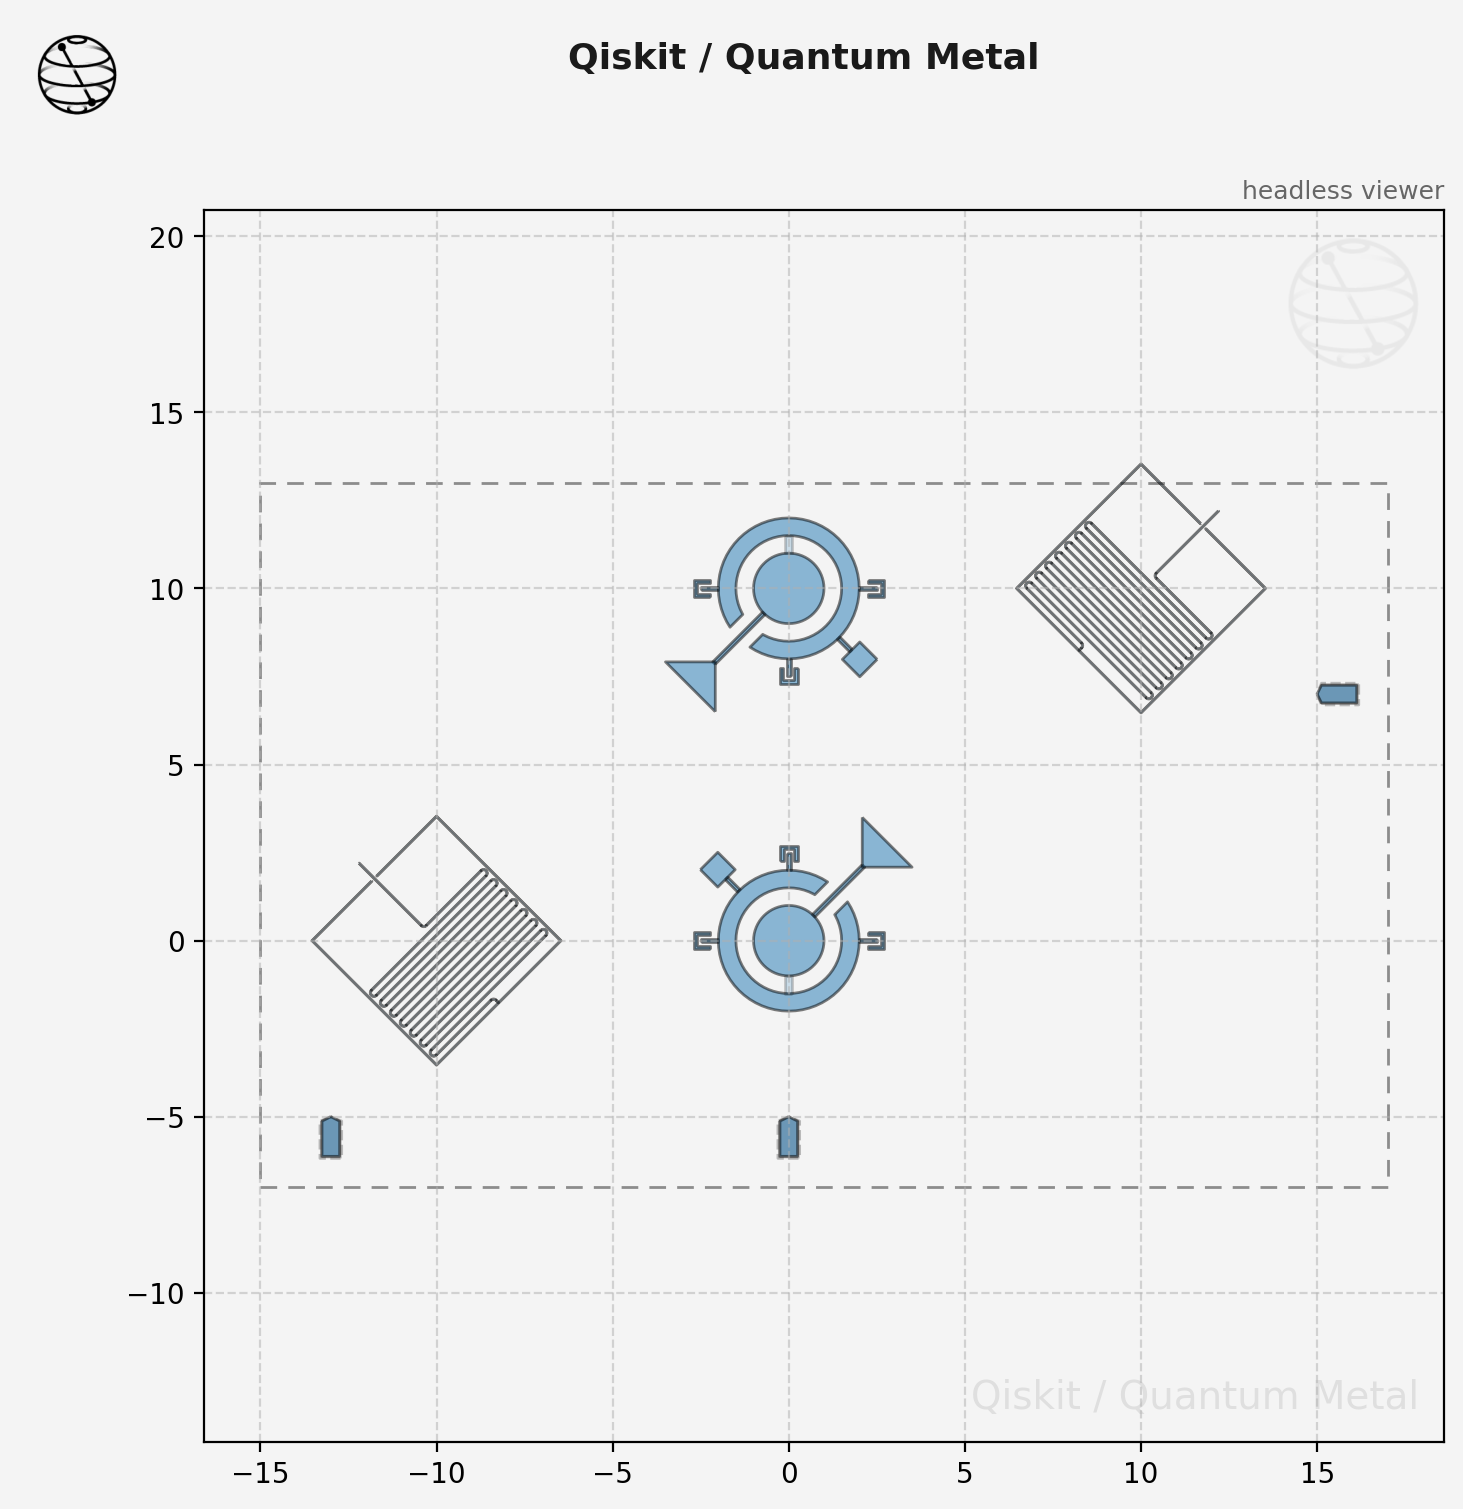

In [51]:
q1 = TransmonConcentricType2(
    design, "qubit1", options=dict(pos_x="0.0mm", orientation="-45")
)
q2 = TransmonConcentricType2(
    design, "qubit2", options=dict(pos_y="10.0mm", orientation="135")
)
res1 = ResonatorLumped(
    design,
    "resonator1",
    options=dict(pos_x="10.0mm", pos_y="10.0mm", orientation="-45"),
)
res2 = ResonatorLumped(
    design, "resonator2", options=dict(pos_x="-10.0mm", pos_y="0.0mm", orientation="45")
)

pad1 = LaunchpadWirebond(
    design,
    "P1_C",
    options=dict(
        pos_x="0mm",
        pos_y="-5mm",
        orientation="90",
        pad_width="0.5mm",
        pad_height="1mm",
        lead_length="0um",
    ),
)

pad2 = LaunchpadWirebond(
    design,
    "P2_C",
    options=dict(
        pos_x="-13mm",
        pos_y="-5mm",
        orientation="90",
        pad_width="0.5mm",
        pad_height="1mm",
        lead_length="0um",
    ),
)

pad3 = LaunchpadWirebond(
    design,
    "P3_C",
    options=dict(
        pos_x="15mm",
        pos_y="7mm",
        orientation="180",
        pad_width="0.5mm",
        pad_height="1mm",
        lead_length="0um",
    ),
)
gui.rebuild()
gui.autoscale()

Now let's connect everything with CPWs:

  self.tables[kind] = pd.concat(



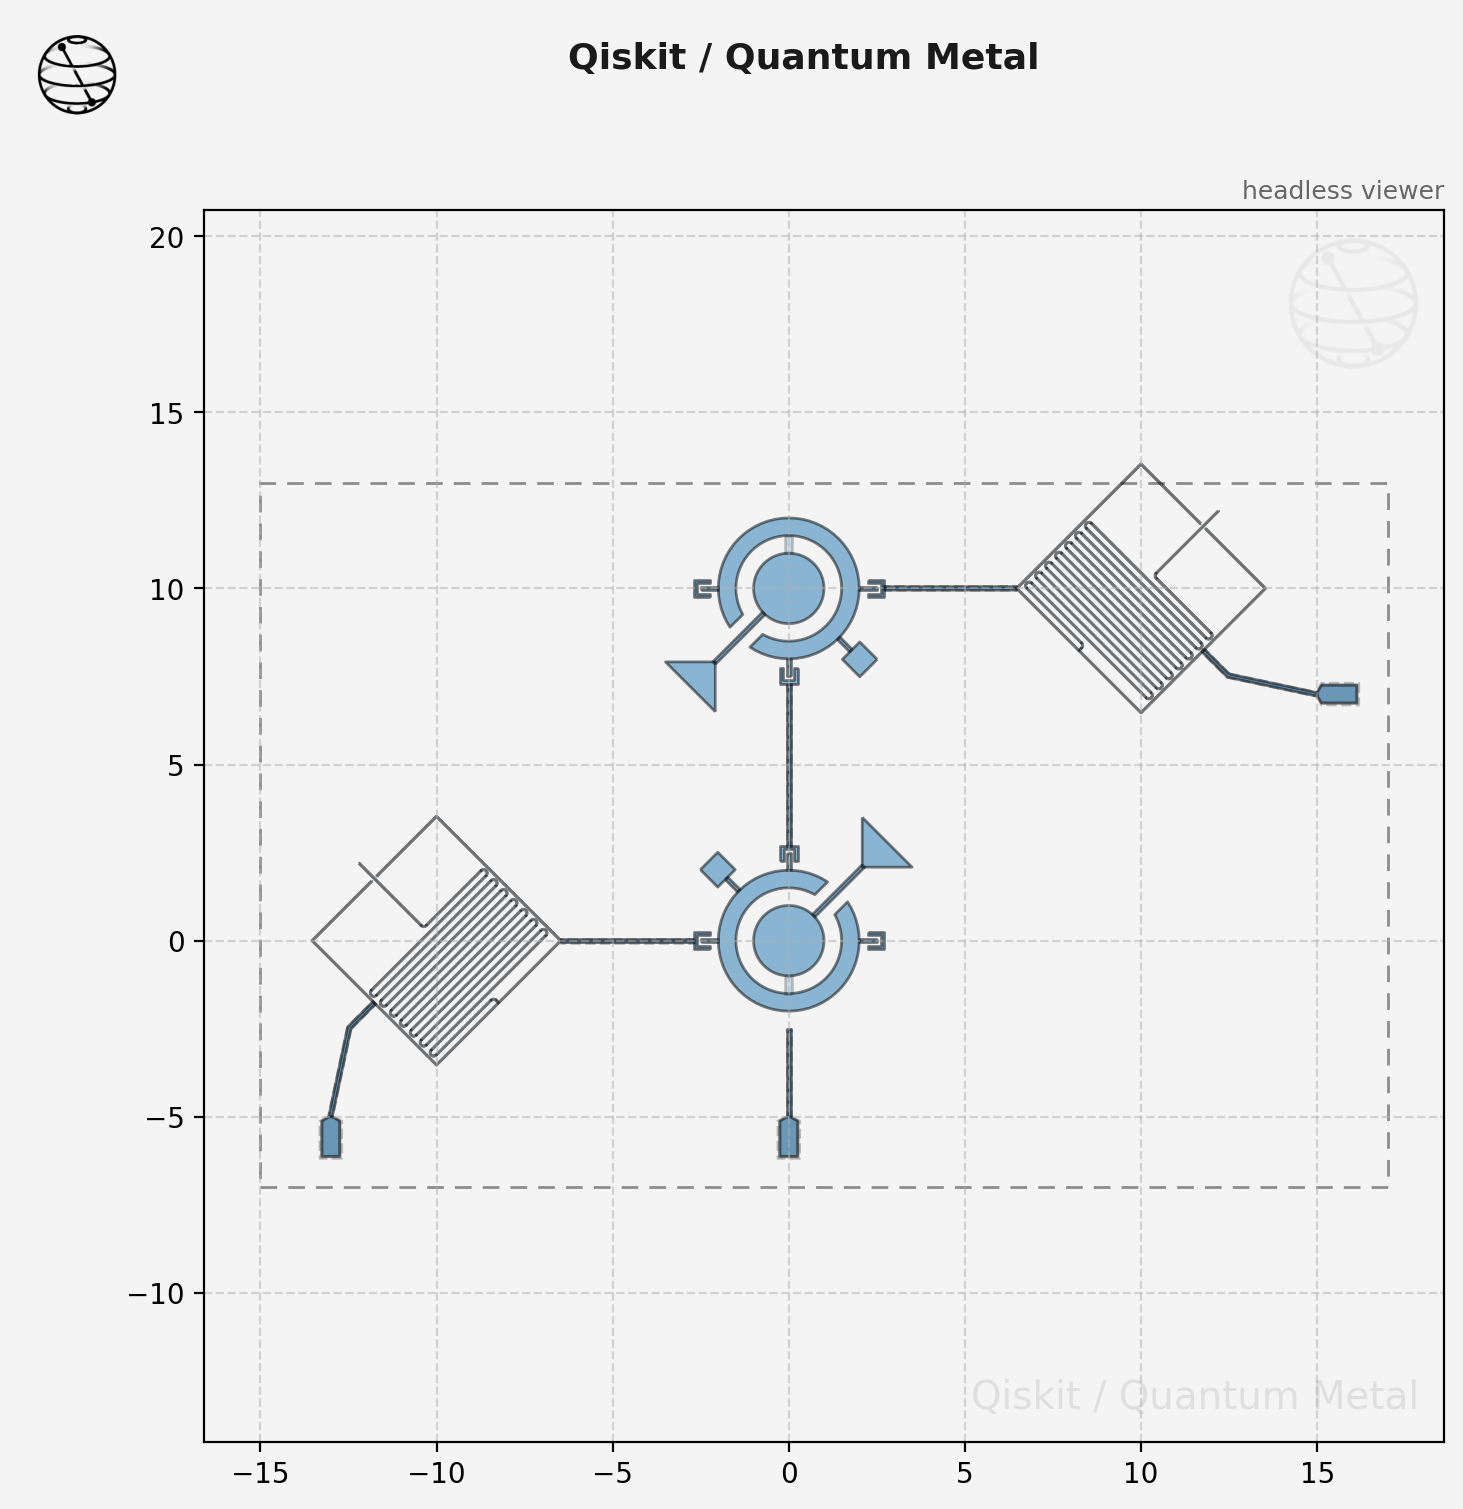

In [52]:
design.variables["cpw_width"] = "0.1mm"

# Connect the two qubits
route1 = RouteStraight(
    design,
    "route1",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="qubit1", pin="pin2"),
            end_pin=Dict(component="qubit2", pin="pin2"),
        ),
        lead=Dict(start_straight="0.0mm", end_straight="0.0mm"),
    ),
)

# Connect top qubit to lumped resonator
route2 = RouteStraight(
    design,
    "route2",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="resonator1", pin="pin_sw"),
            end_pin=Dict(component="qubit2", pin="pin3"),
        ),
        lead=Dict(start_straight="0.0mm", end_straight="0.0mm"),
    ),
)

# Connect bottom qubit to lumped resonator
route3 = RouteStraight(
    design,
    "route3",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="resonator2", pin="pin_se"),
            end_pin=Dict(component="qubit1", pin="pin3"),
        ),
        lead=Dict(start_straight="0.0mm", end_straight="0.0mm"),
    ),
)

# Connect top lumped resonator to launch pad
route4 = RouteStraight(
    design,
    "route4",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="resonator1", pin="pin_east"),
            end_pin=Dict(component="P3_C", pin="tie"),
        ),
        lead=Dict(start_straight="1mm", end_straight="0.0mm"),
    ),
)

# Connect bottom lumped resonator to launch pad
route5 = RouteStraight(
    design,
    "route5",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="resonator2", pin="pin_west"),
            end_pin=Dict(component="P2_C", pin="tie"),
        ),
        lead=Dict(start_straight="1mm", end_straight="0.0mm"),
    ),
)

from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround

otg11 = OpenToGround(
    design, "open1i", options=dict(pos_x="0mm", pos_y="-2.5mm", orientation="90")
)

# Connect bottom qubit to launch pad
route5 = RouteStraight(
    design,
    "route6",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="open1i", pin="open"),
            end_pin=Dict(component="P1_C", pin="tie"),
        ),
        lead=Dict(start_straight="0mm", end_straight="0.0mm"),
    ),
)


gui.rebuild()
gui.autoscale()

And we're done! Here's a look at the final full chip design:

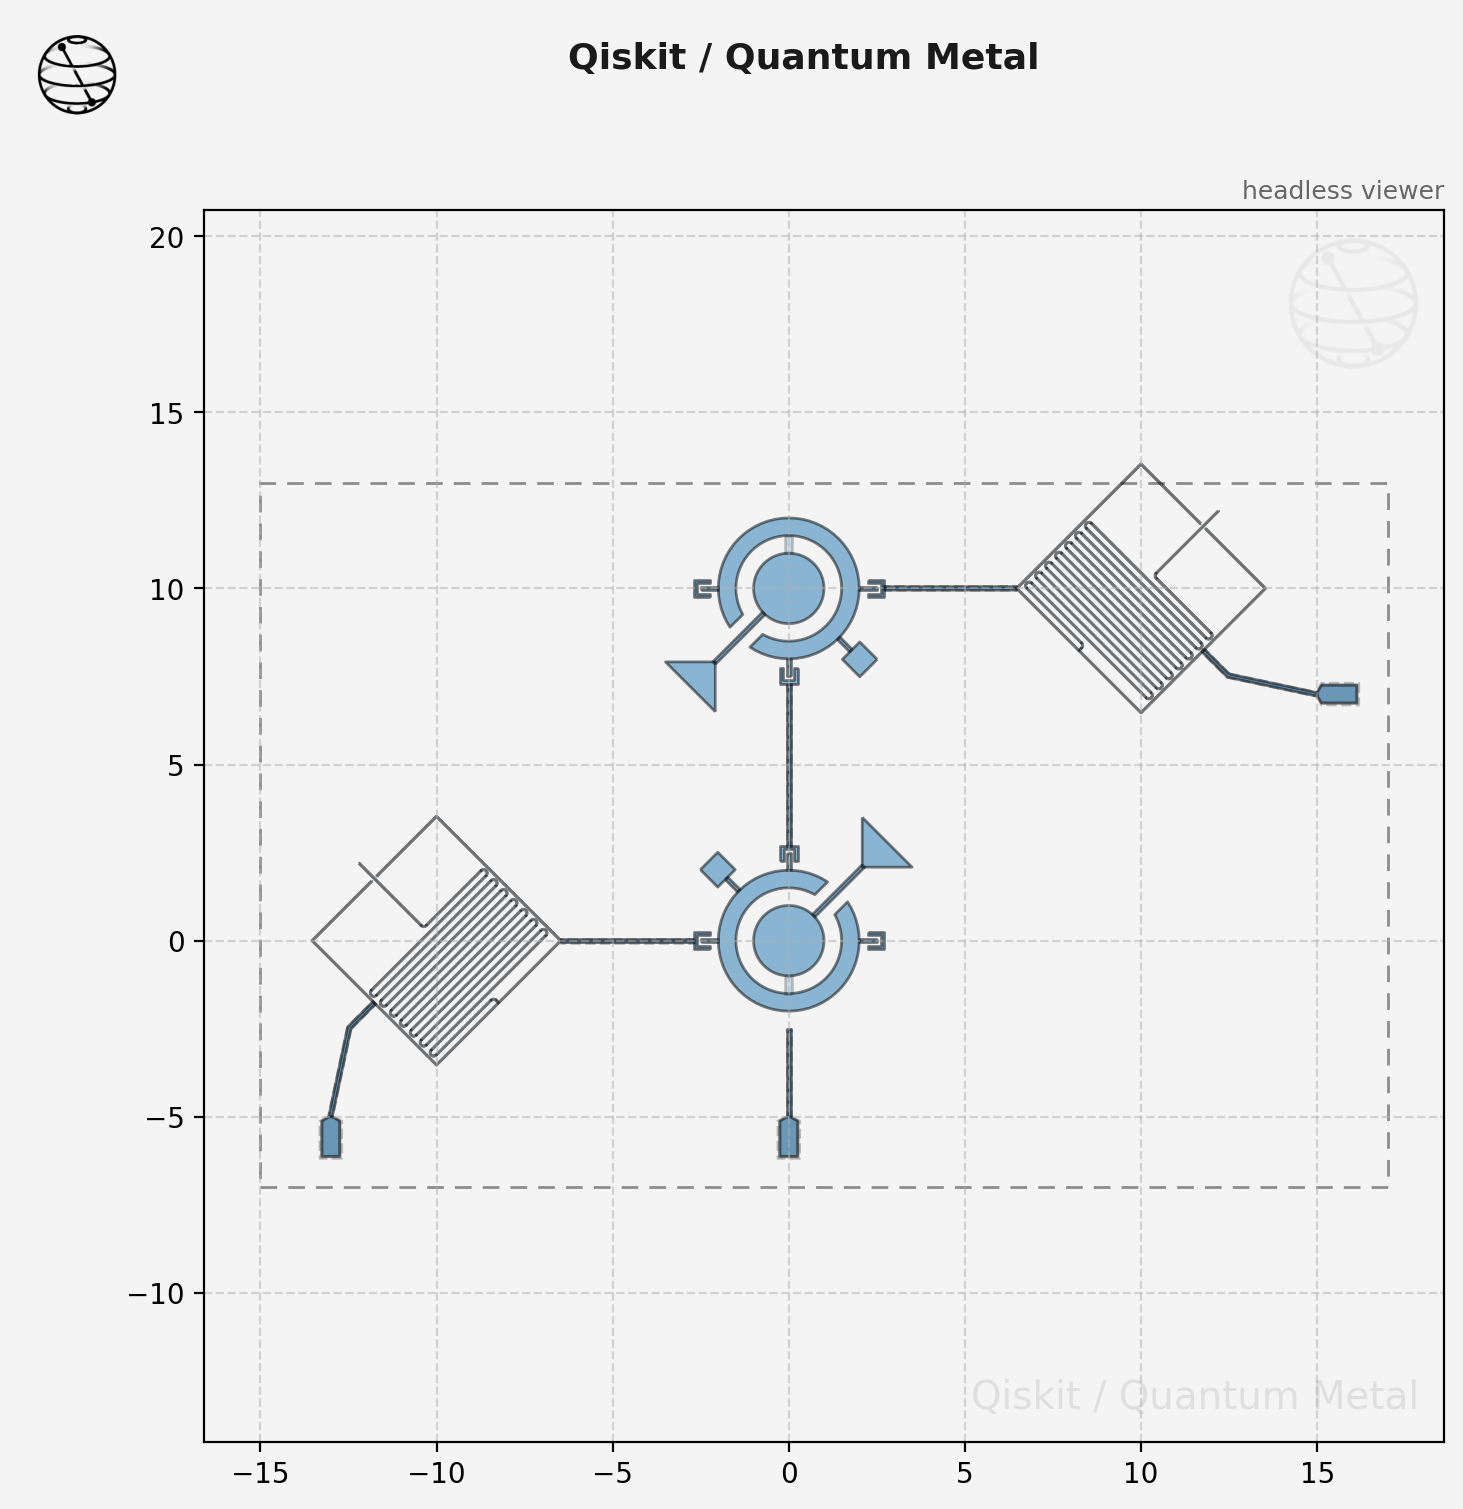

In [53]:
gui.screenshot()

## Example 2: two fixed-frequency transmons and a flux-tunable coupler

First delete the components of the previous design and resize the chip for this one:

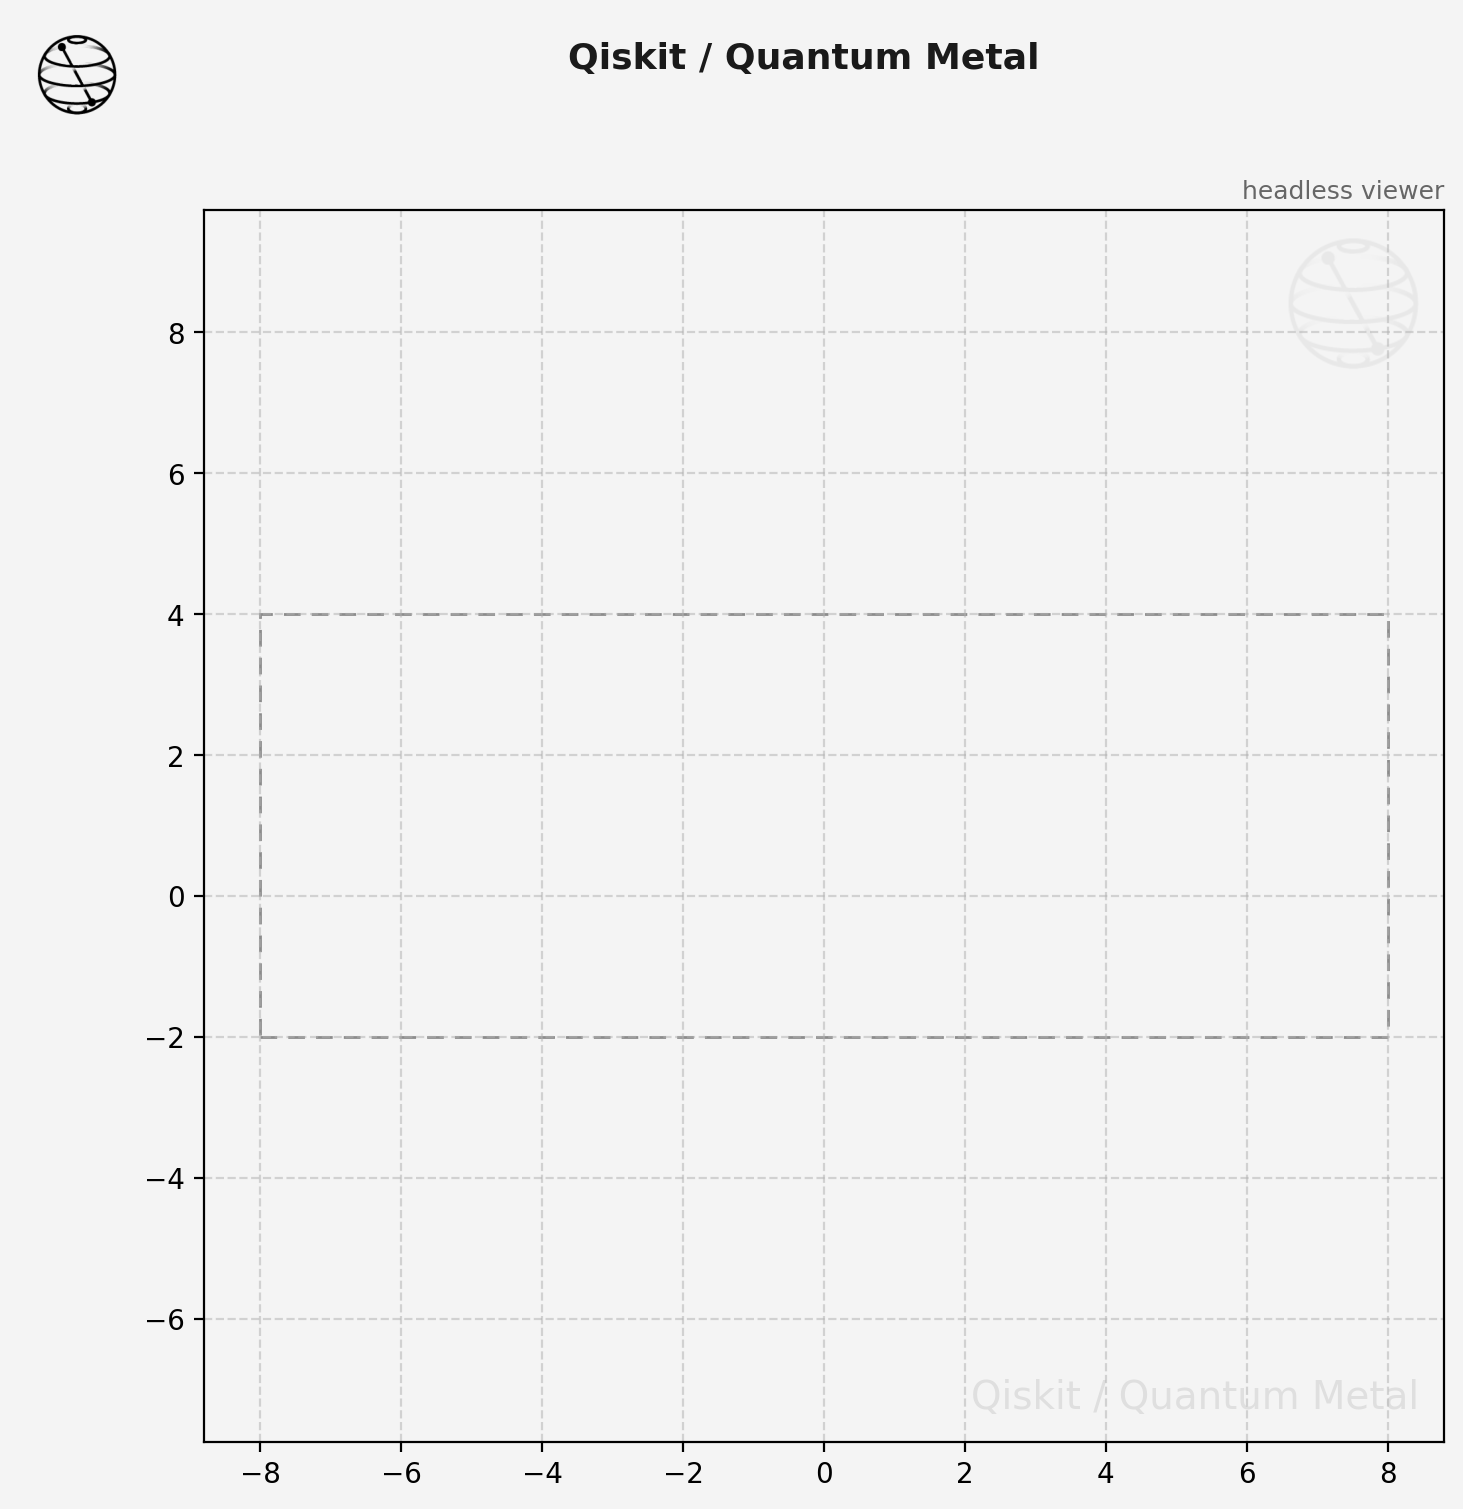

In [54]:
design.delete_all_components()
design.chips.main.size.update(
    size_x="16mm", size_y="6mm", center_x="0mm", center_y="1mm"
)
gui.rebuild()
gui.autoscale()

Now let's instantiate the six components used in this design: two transmon pocket qubits, a flux tunable qubit and three launch pads:

In [55]:
from qiskit_metal.qlibrary.qubits.transmon_pocket_6 import TransmonPocket6
from qiskit_metal.qlibrary.couplers.tunable_coupler_02 import TunableCoupler02
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond

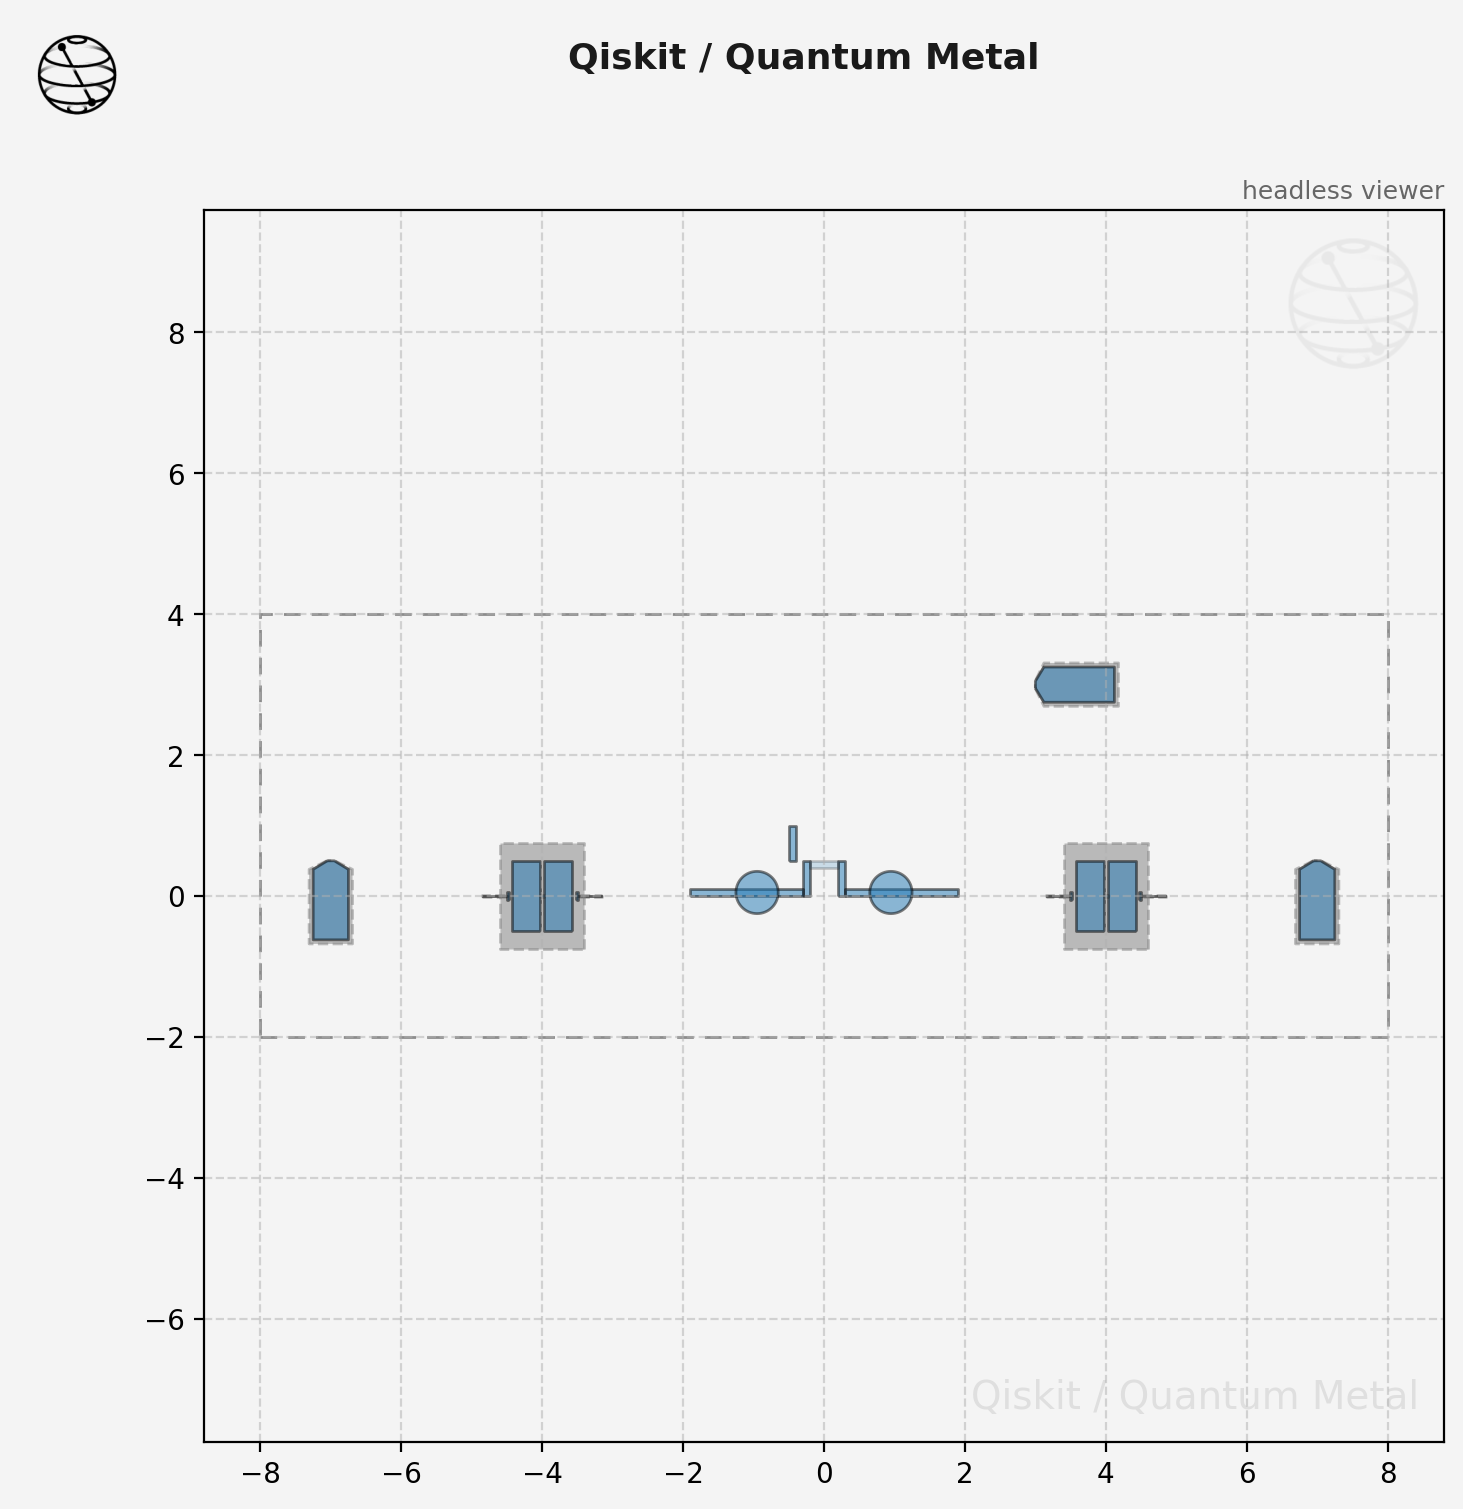

In [56]:
Q1 = TransmonPocket6(
    design,
    "Q1",
    options=dict(
        pos_x="-4mm",
        pos_y="0.0mm",
        orientation="90",
        pad_width="1mm",
        pad_height="0.4mm",
        pocket_width="1.5mm",
        pocket_height="1.2mm",
        pad_gap="0.05mm",
        connection_pads=dict(
            bus_03=dict(loc_W=0, loc_H=-1, pad_width="100um", pad_gap="50um"),
            readout=dict(loc_W=0, loc_H=1, pad_width="100um", pad_gap="50um"),
        ),
    ),
)

Q2 = TransmonPocket6(
    design,
    "Q2",
    options=dict(
        pos_x="4mm",
        pos_y="0.0mm",
        orientation="90",
        pad_width="1mm",
        pad_height="0.4mm",
        pocket_width="1.5mm",
        pocket_height="1.2mm",
        pad_gap="0.05mm",
        connection_pads=dict(
            bus_03=dict(loc_W=0, loc_H=-1, pad_width="100um", pad_gap="50um"),
            readout=dict(loc_W=0, loc_H=1, pad_width="100um", pad_gap="50um"),
        ),
    ),
)


TC = TunableCoupler02(design, "TC")

pad1 = LaunchpadWirebond(
    design,
    "P1_C",
    options=dict(
        pos_x="-7mm",
        pos_y="0.5mm",
        orientation="90",
        pad_width="0.5mm",
        pad_height="1mm",
        lead_length="0um",
    ),
)

pad2 = LaunchpadWirebond(
    design,
    "P2_C",
    options=dict(
        pos_x="7mm",
        pos_y="0.5mm",
        orientation="90",
        pad_width="0.5mm",
        pad_height="1mm",
        lead_length="0um",
    ),
)

pad3 = LaunchpadWirebond(
    design,
    "P3_C",
    options=dict(
        pos_x="3mm",
        pos_y="3mm",
        orientation="-180",
        pad_width="0.5mm",
        pad_height="1mm",
        lead_length="0um",
    ),
)
gui.rebuild()
gui.autoscale()

Now we can connect all of the components with CPWs:

  self.tables[kind] = pd.concat(



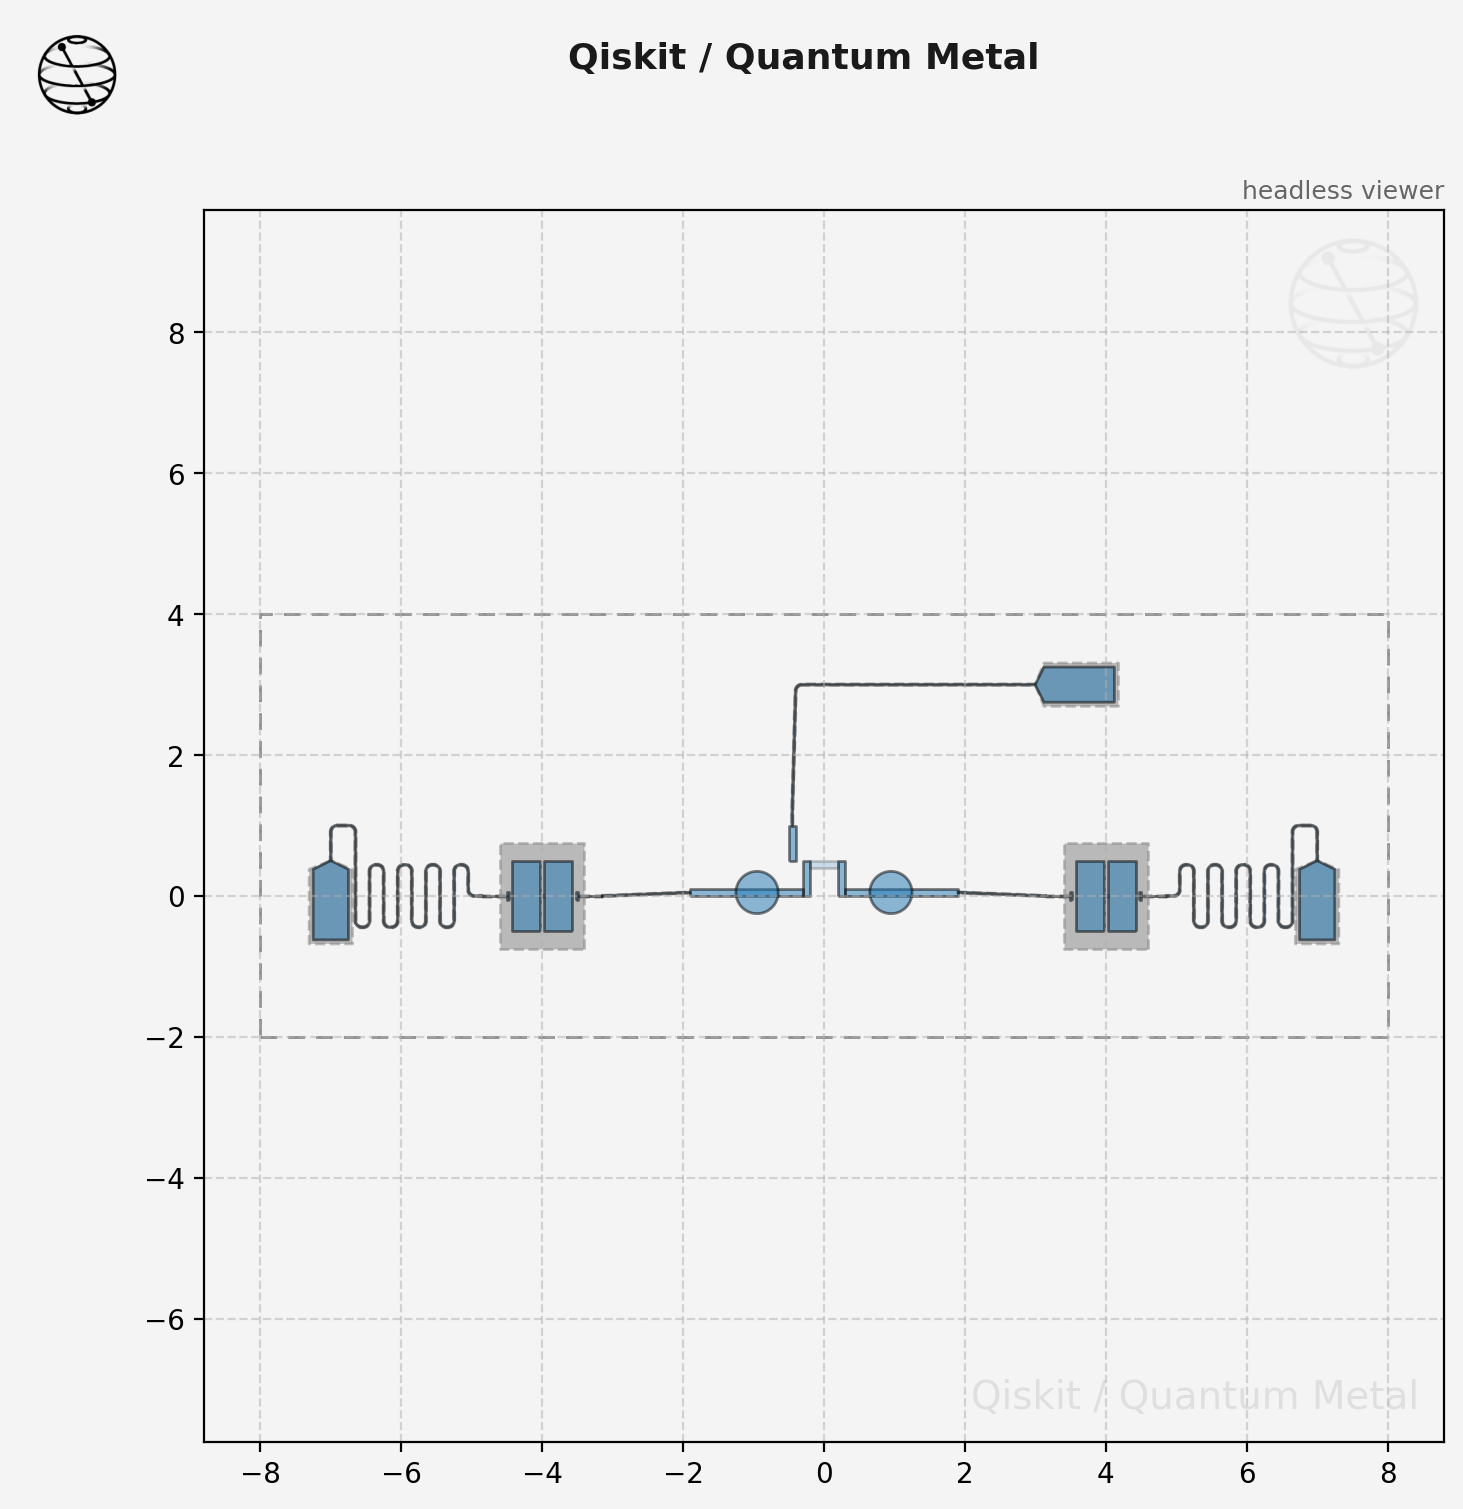

In [57]:
design.variables["cpw_width"] = "0.01mm"

# Connect the two qubits
route1 = RouteStraight(
    design,
    "route1",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="Q1", pin="bus_03"),
            end_pin=Dict(component="TC", pin="pin2"),
        ),
        lead=Dict(start_straight="0.0mm", end_straight="0.0mm"),
    ),
)

route2 = RouteStraight(
    design,
    "route2",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="Q2", pin="readout"),
            end_pin=Dict(component="TC", pin="pin1"),
        ),
        lead=Dict(start_straight="0.0mm", end_straight="0.0mm"),
    ),
)

route3 = RouteStraight(
    design,
    "route3",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="P3_C", pin="tie"),
            end_pin=Dict(component="TC", pin="fbl"),
        ),
        lead=Dict(start_straight="3.4mm", end_straight="0.2mm"),
        fillet="90um",
    ),
)

route4 = RouteMeander(
    design,
    "route4",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="Q1", pin="readout"),
            end_pin=Dict(component="P1_C", pin="tie"),
        ),
        lead=Dict(start_straight="0.2mm", end_straight="0.5mm"),
        meander=Dict(asymmetry="0mm"),
        total_length="10mm",
        fillet="90um",
    ),
)

route5 = RouteMeander(
    design,
    "route5",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="Q2", pin="bus_03"),
            end_pin=Dict(component="P2_C", pin="tie"),
        ),
        lead=Dict(start_straight="0.2mm", end_straight="0.5mm"),
        meander=Dict(asymmetry="0mm"),
        total_length="10mm",
        fillet="90um",
    ),
)

gui.rebuild()
gui.autoscale()

Here's a look at the final, complete design:

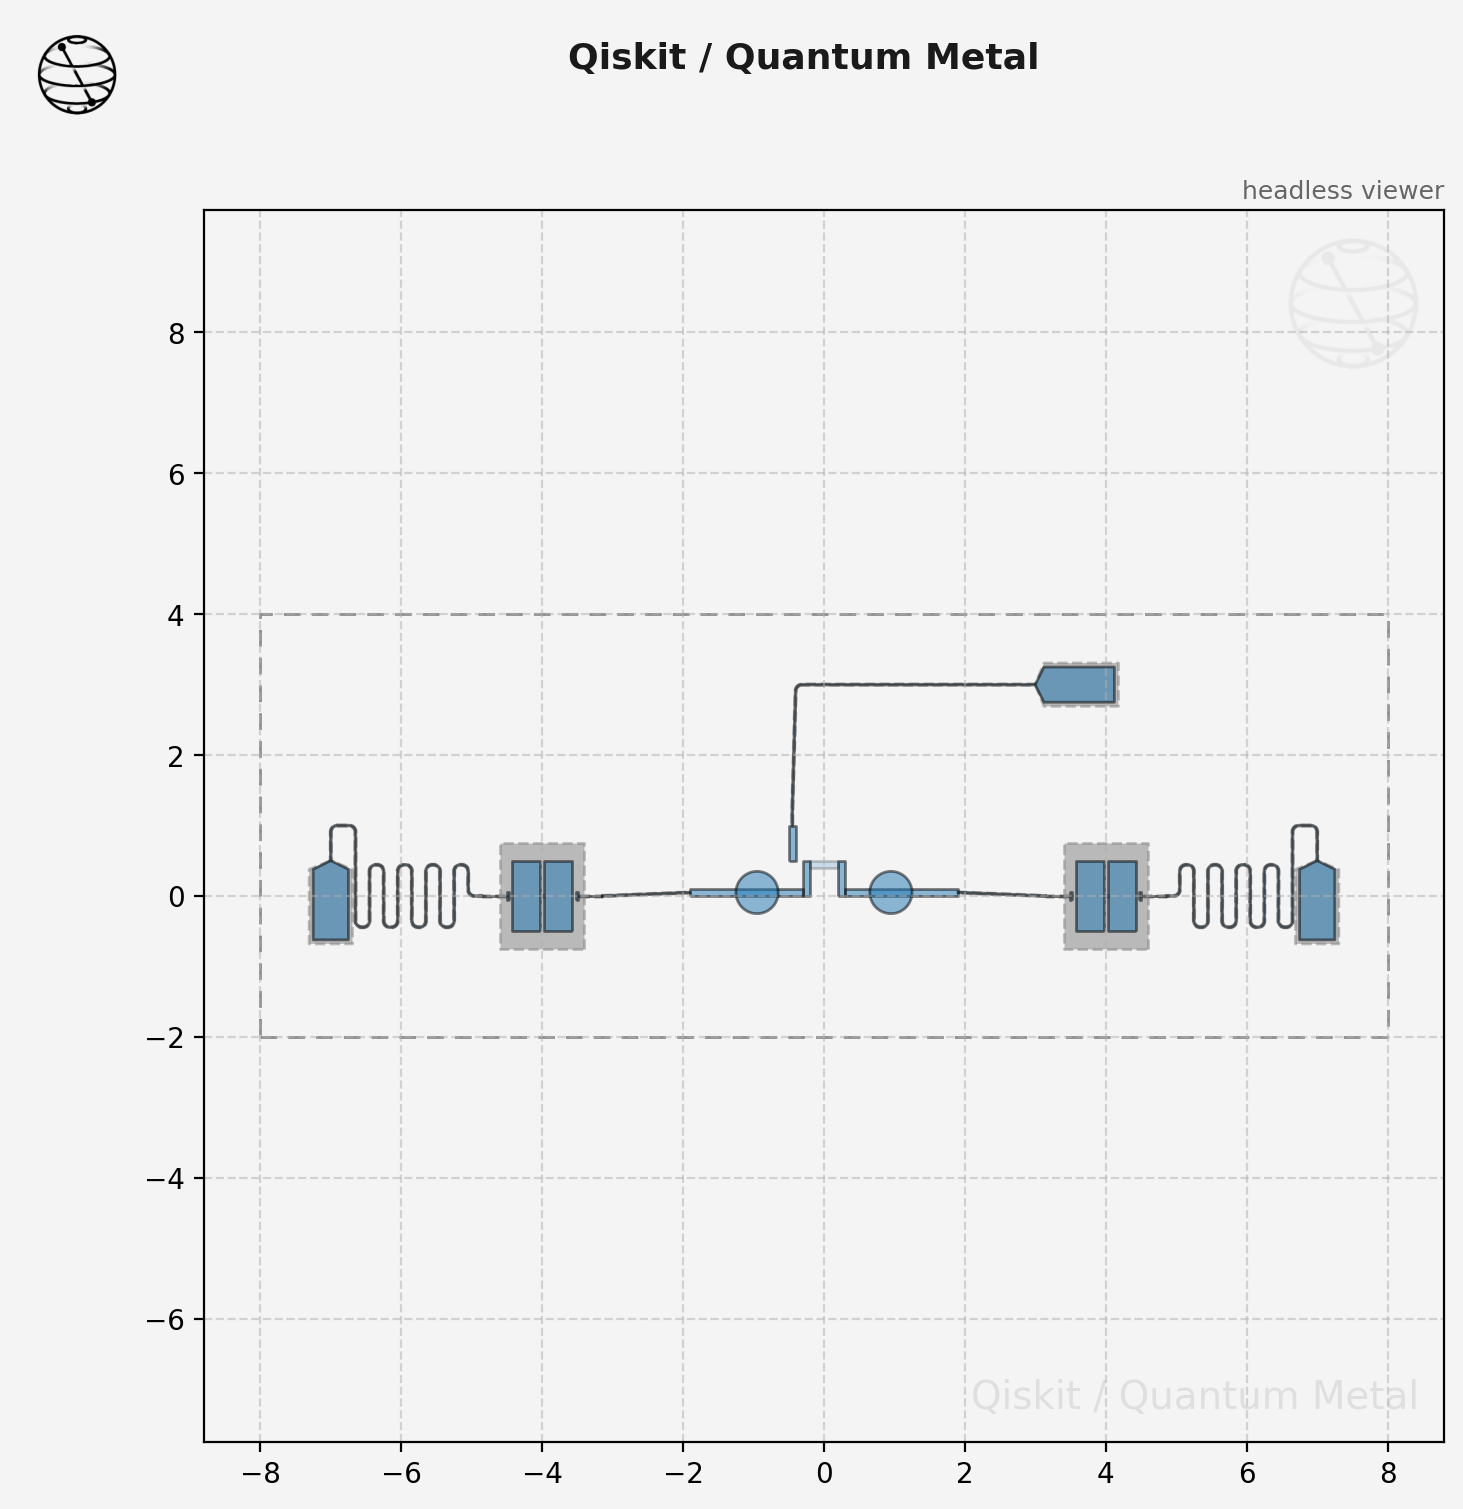

In [58]:
gui.screenshot()

The above design closely matches the chip design depicted in Fig. 1 of Phys. Rev. Research 2, 033447 (2020).

## Example 3: two fixed-frequency Xmon qubits and a tunable coupler

This third example is similar to the preceding one but uses Xmon qubits (instead of transmon pockets) and an interdigitated capacitive coupler. Again, start by deleting the previous design:

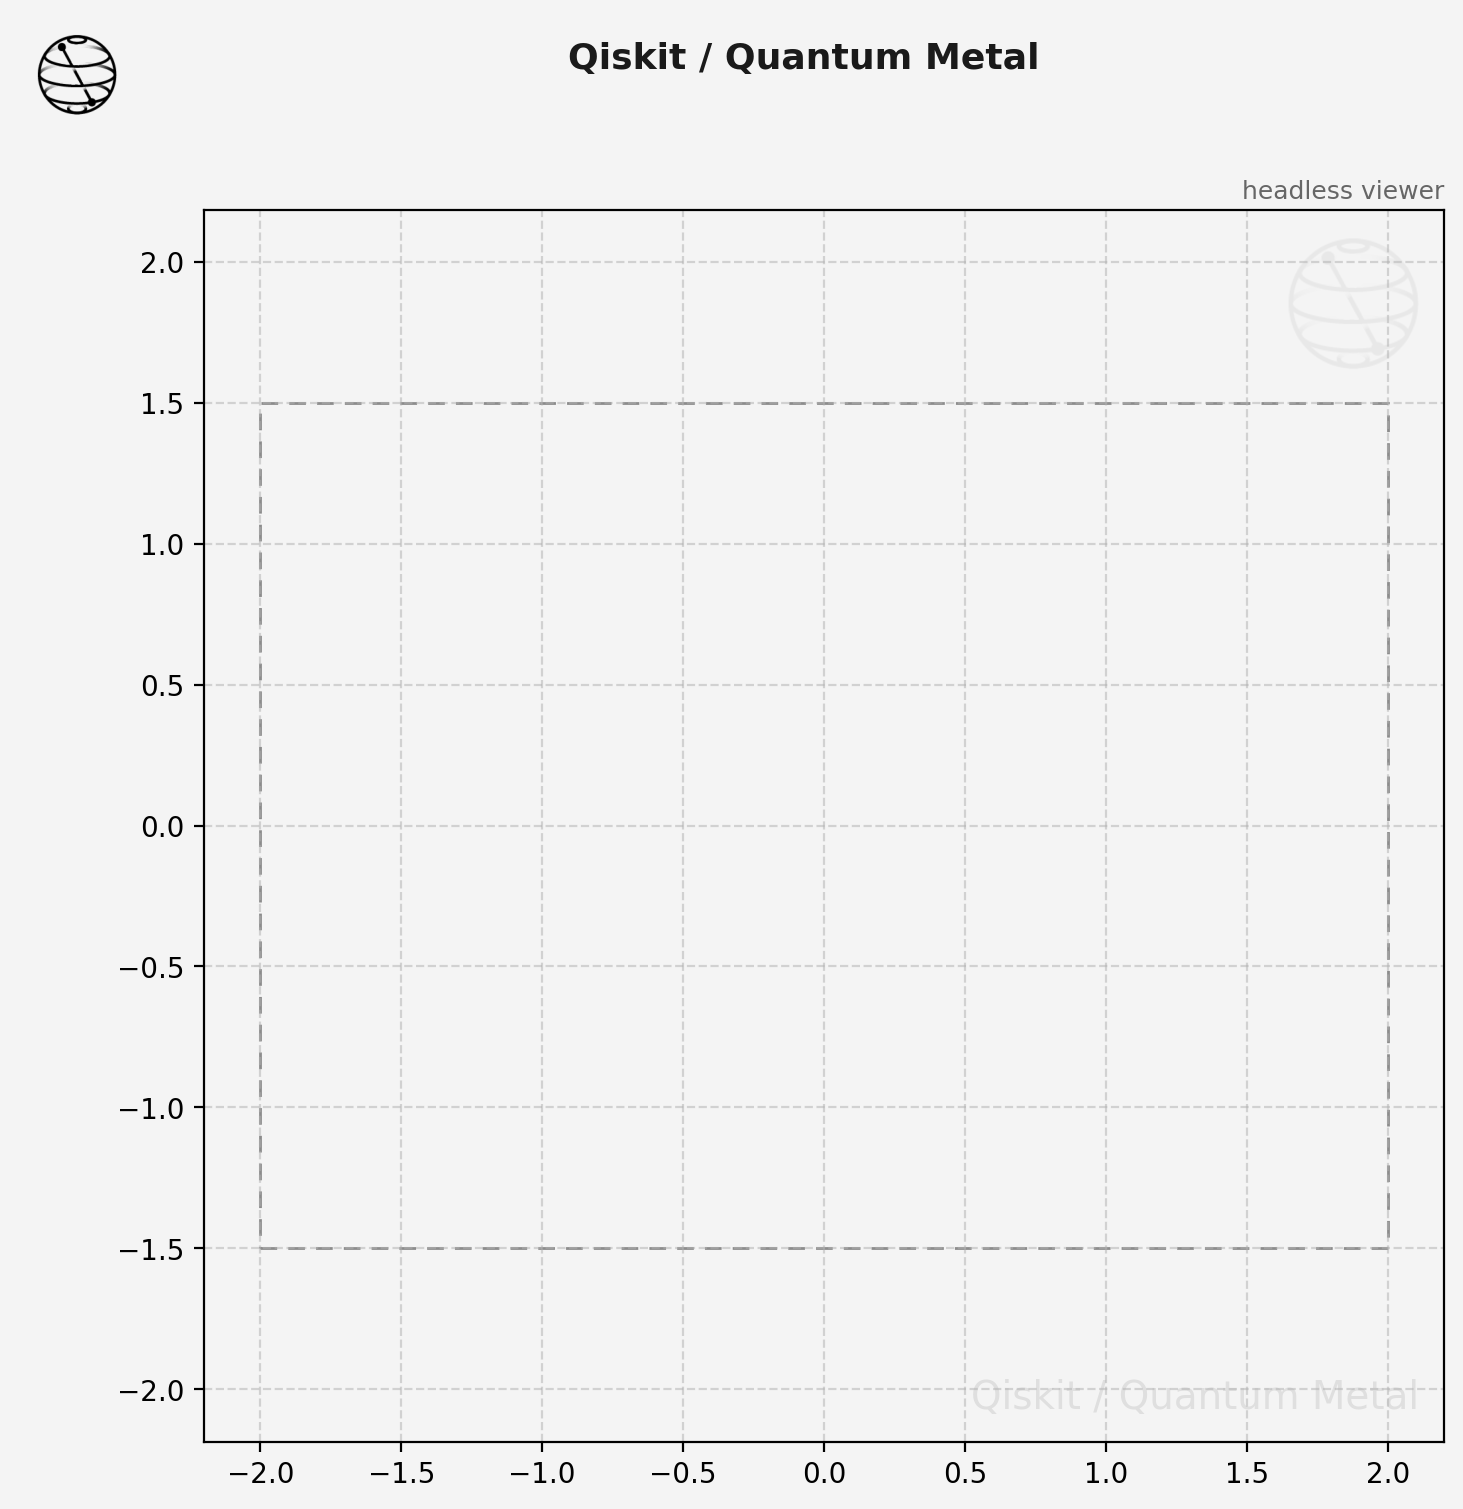

In [59]:
design.delete_all_components()
design.chips.main.size.update(
    size_x="4mm", size_y="3mm", center_x="0mm", center_y="0mm"
)
gui.rebuild()
gui.autoscale()

In [60]:
from qiskit_metal.qlibrary.couplers.tunable_coupler_01 import TunableCoupler01
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond

In [61]:
design.chips.main

{'material': 'silicon',
 'layer_start': '0',
 'layer_end': '2048',
 'size': {'center_x': '0mm',
  'center_y': '0mm',
  'center_z': '0.0mm',
  'size_x': '4mm',
  'size_y': '3mm',
  'size_z': '-750um',
  'sample_holder_top': '890um',
  'sample_holder_bottom': '1650um'}}

We will first place the two X-mon qubits with the flux-tunable coupler located between them:

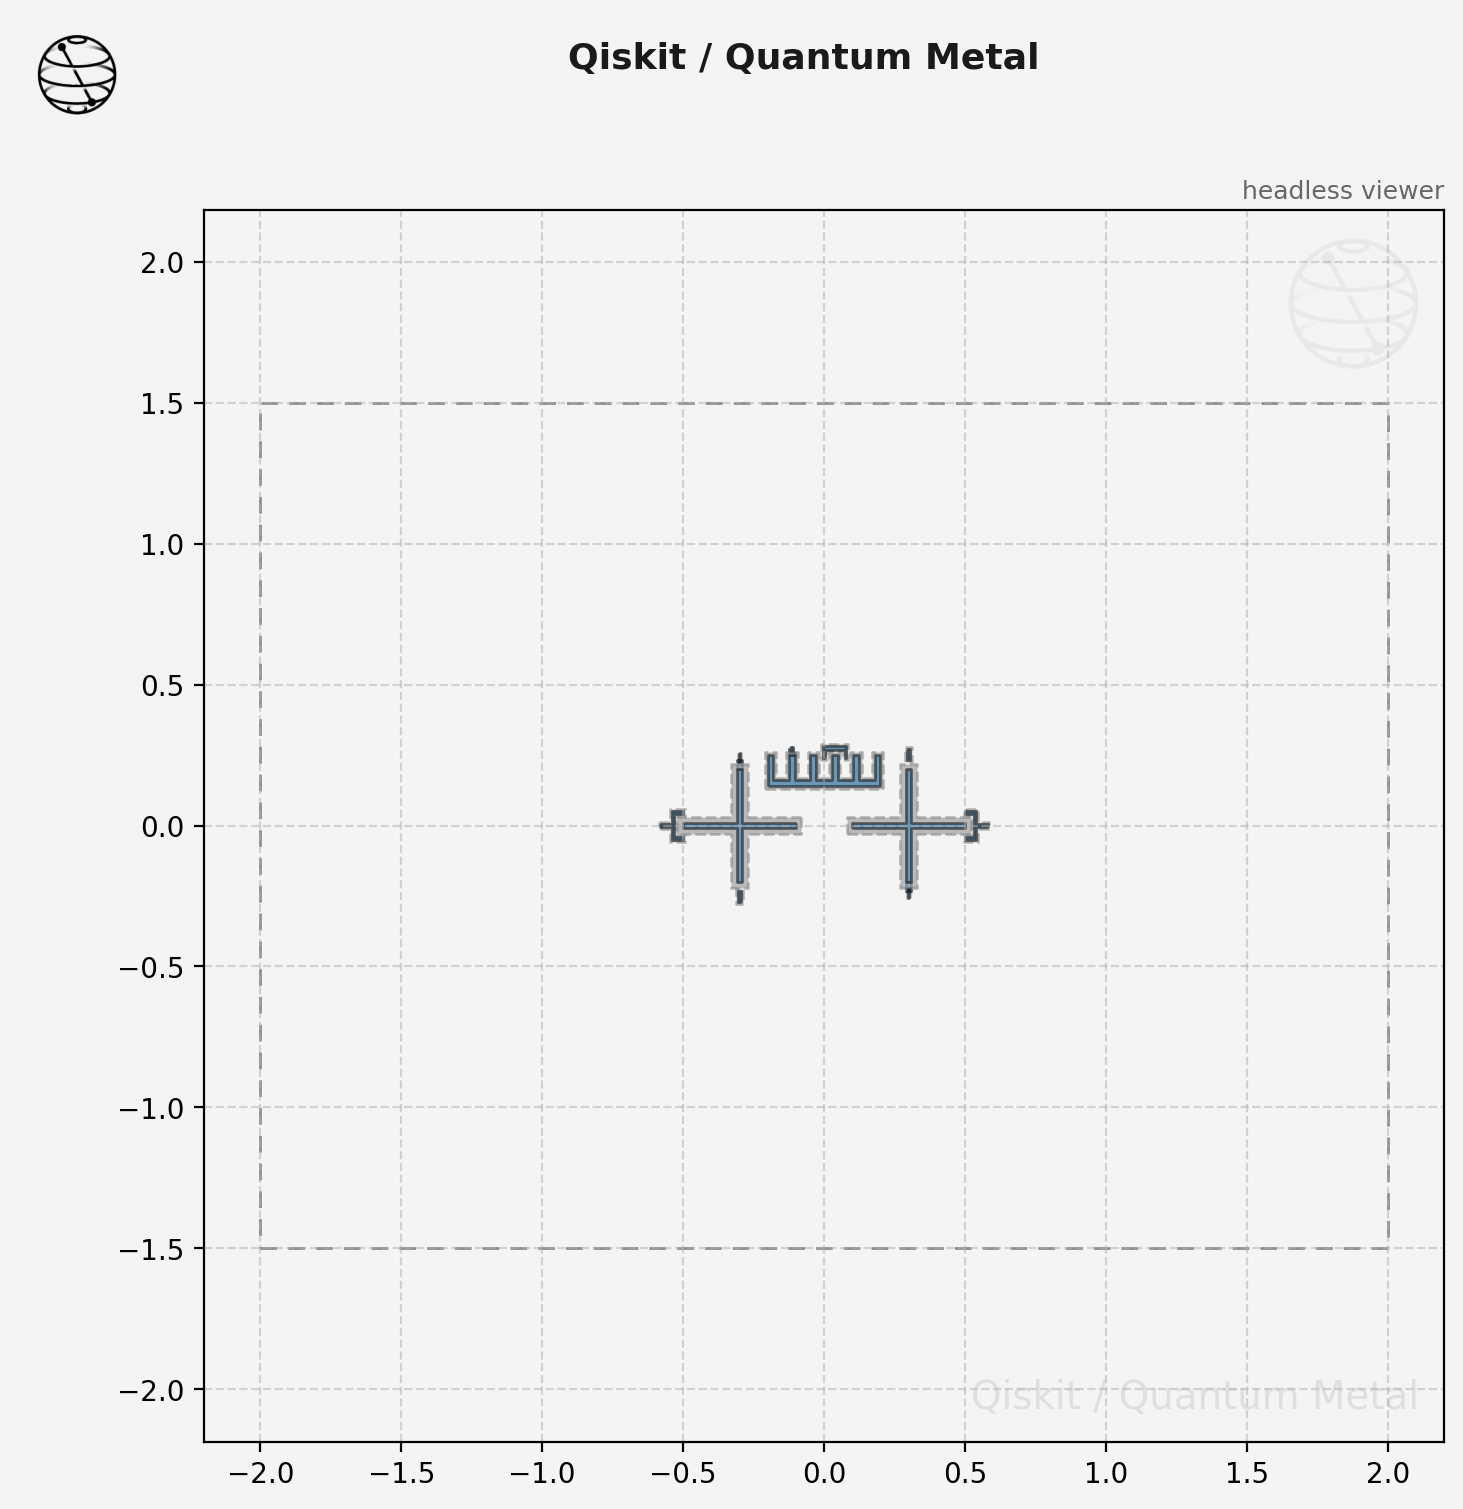

In [62]:
xmon_options1 = dict(
    connection_pads=dict(
        # a = dict( connector_location = '0', connector_type = '0'),
        b=dict(connector_location="90", connector_type="1"),
        c=dict(connector_location="180", connector_type="0"),
    ),
    pos_x="0.3mm",
)

xmon_options2 = dict(
    connection_pads=dict(
        # a = dict( connector_location = '0', connector_type = '0'),
        b=dict(connector_location="90", connector_type="1"),
        c=dict(connector_location="180", connector_type="0"),
    ),
    pos_x="-0.3mm",
    orientation="180",
)

# Create a new Transmon Cross object with name 'Q1'
q1 = TransmonCrossFL(design, "Q1", options=xmon_options1)
q2 = TransmonCrossFL(design, "Q2", options=xmon_options2)

TC = TunableCoupler01(design, "TC", options=dict(pos_y="0.15mm", a_height="100um"))

gui.rebuild()
gui.autoscale()

Next, we will place the launch pads:

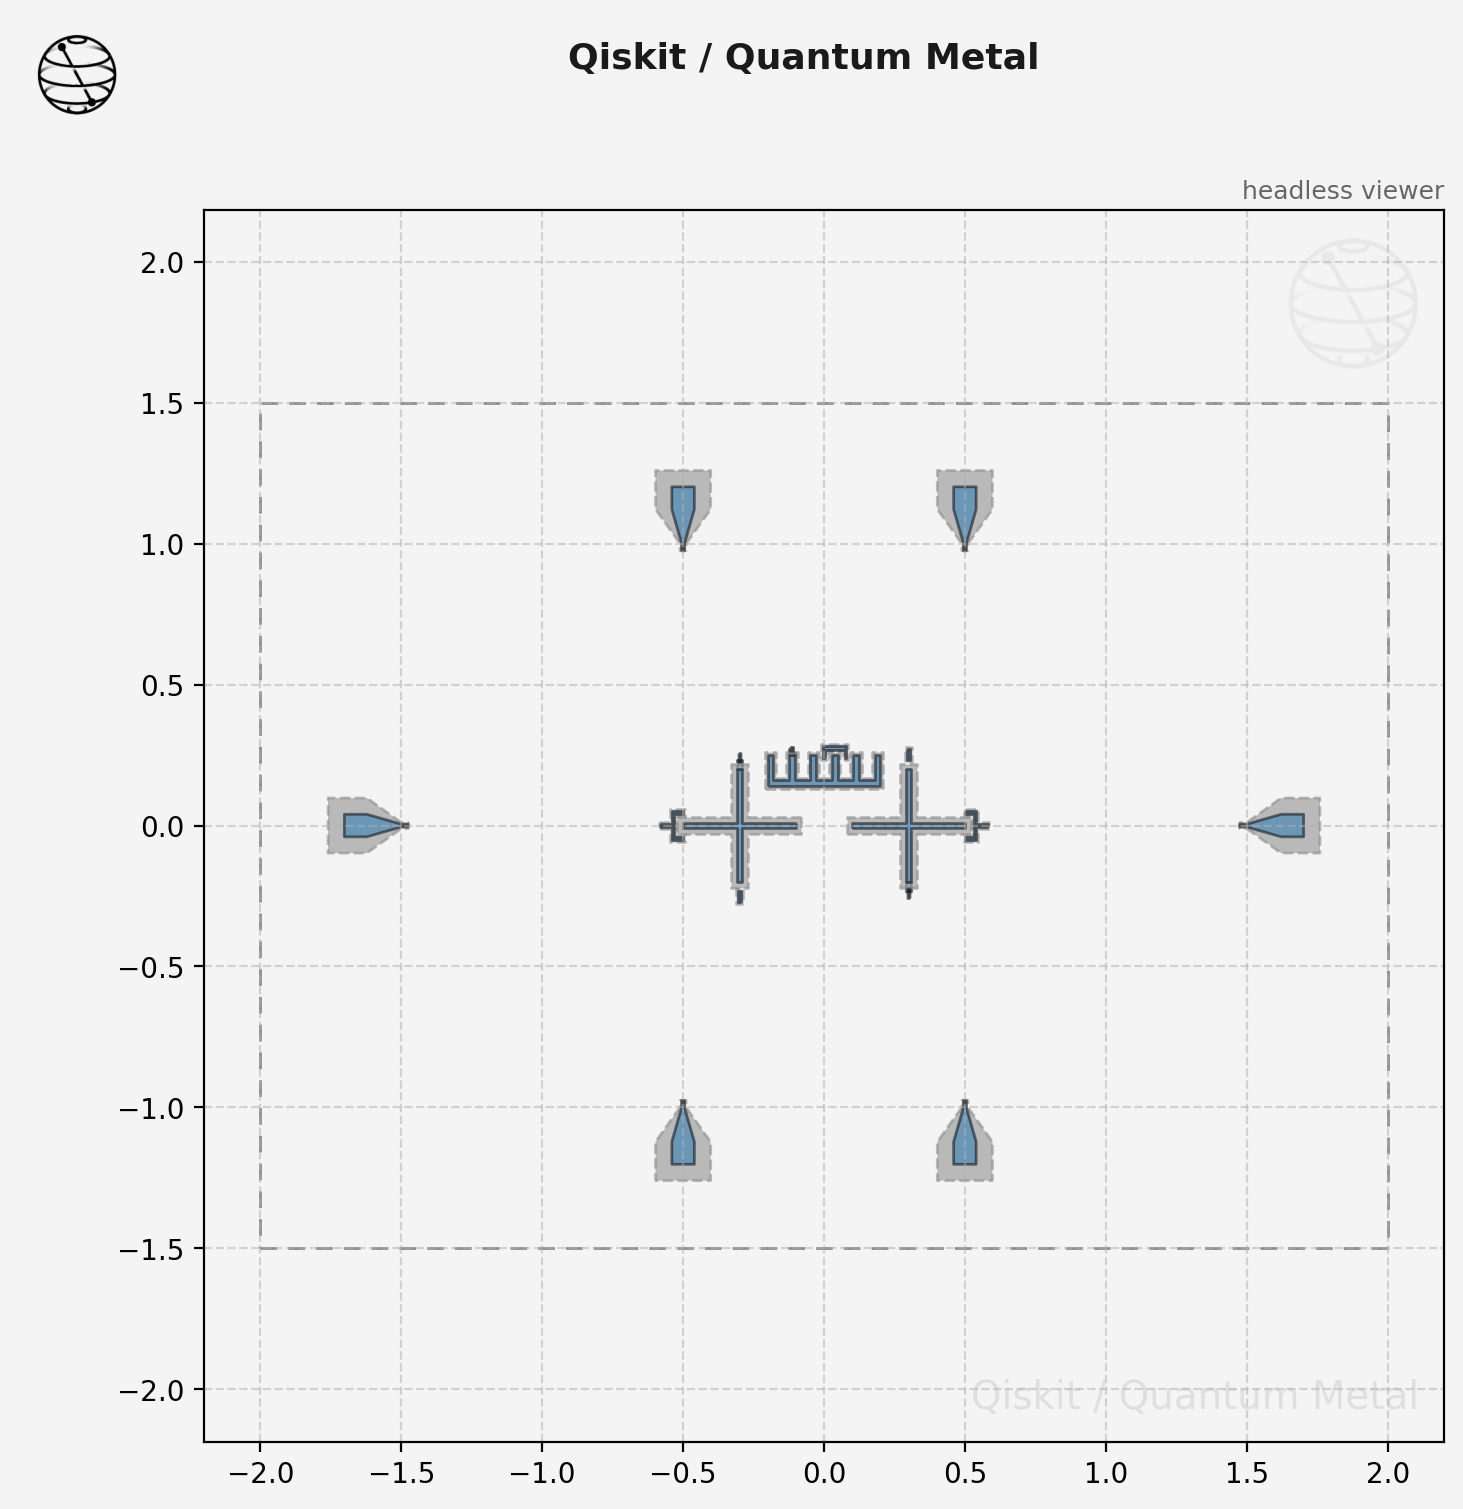

In [63]:
T_west = LaunchpadWirebond(
    design,
    "T_west",
    options=dict(
        pos_x="-1.5mm",
        pos_y="0.0mm",
    ),
)

T_east = LaunchpadWirebond(
    design,
    "T_east",
    options=dict(
        pos_x="1.5mm",
        pos_y="0.0mm",
        orientation="180",
    ),
)

T_NE = LaunchpadWirebond(
    design,
    "T_NE",
    options=dict(
        pos_x="0.5mm",
        pos_y="1mm",
        orientation="-90",
    ),
)

T_NW = LaunchpadWirebond(
    design,
    "T_NW",
    options=dict(
        pos_x="-0.5mm",
        pos_y="1mm",
        orientation="-90",
    ),
)

T_SW = LaunchpadWirebond(
    design,
    "T_SW",
    options=dict(
        pos_x="-0.5mm",
        pos_y="-1mm",
        orientation="90",
    ),
)

T_SE = LaunchpadWirebond(
    design,
    "T_SE",
    options=dict(
        pos_x="0.5mm",
        pos_y="-1mm",
        orientation="90",
    ),
)

gui.rebuild()
gui.autoscale()

Next we'll import the relevant routing modules:

In [64]:
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors
from qiskit_metal.qlibrary.tlines.pathfinder import RoutePathfinder
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.framed_path import RouteFramed
from qiskit_metal.qlibrary.tlines.mixed_path import RouteMixed

We'll create the straight routing segments first, which connect the top/bottom launch pads with the qubits and coupler:

  self.tables[kind] = pd.concat(



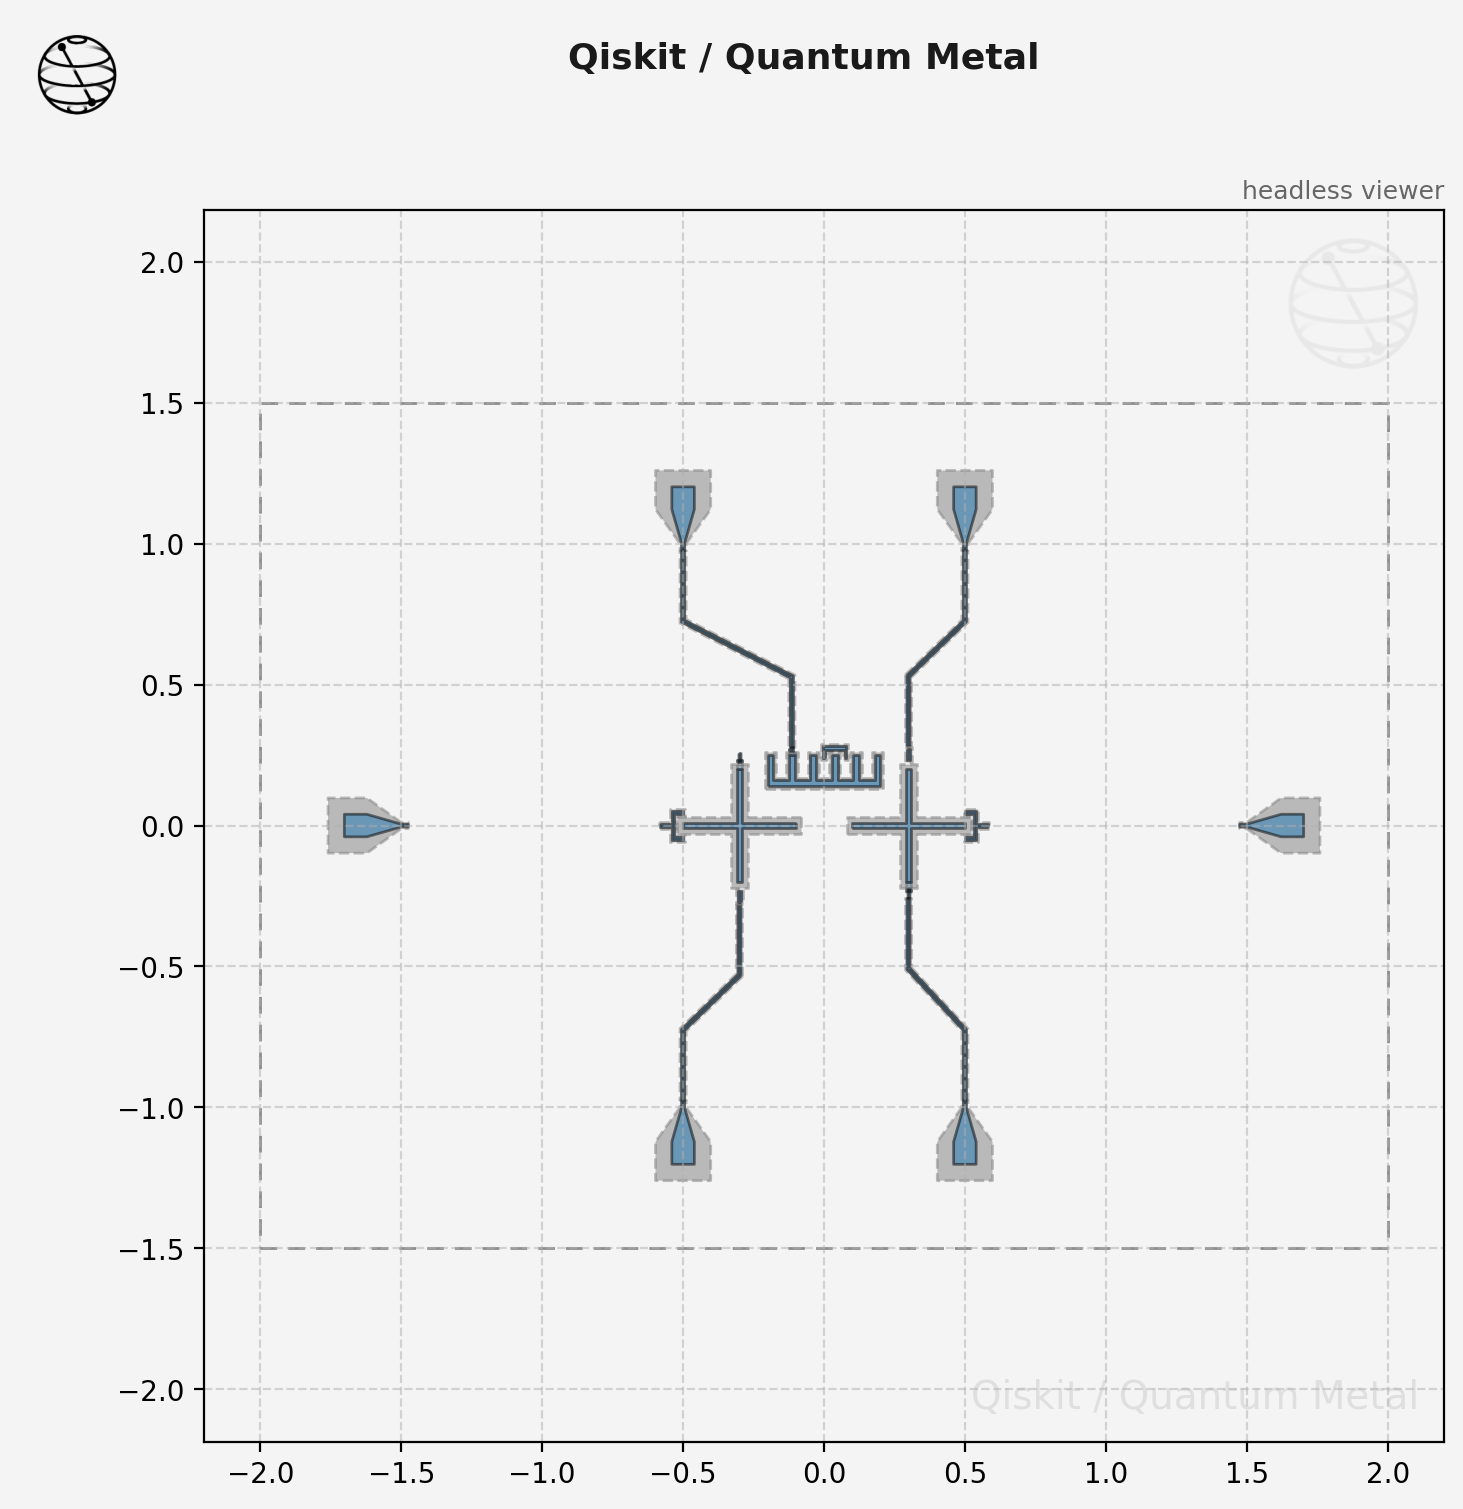

In [65]:
route1 = RouteStraight(
    design,
    "cpw_1",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="Q1", pin="flux_line"),
            end_pin=Dict(component="T_SE", pin="tie"),
        ),
        lead=Dict(start_straight="0.25mm", end_straight="0.25mm"),
    ),
)

route2 = RouteStraight(
    design,
    "cpw_2",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="Q2", pin="b"),
            end_pin=Dict(component="T_SW", pin="tie"),
        ),
        lead=Dict(start_straight="0.25mm", end_straight="0.25mm"),
    ),
)

route3 = RouteStraight(
    design,
    "cpw_3",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="Q1", pin="b"),
            end_pin=Dict(component="T_NE", pin="tie"),
        ),
        lead=Dict(start_straight="0.25mm", end_straight="0.25mm"),
    ),
)

route4 = RouteStraight(
    design,
    "cpw_4",
    options=Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="TC", pin="Flux"),
            end_pin=Dict(component="T_NW", pin="tie"),
        ),
        lead=Dict(start_straight="0.25mm", end_straight="0.25mm"),
    ),
)

gui.rebuild()
gui.autoscale()

Next we'll create the east-west transmission line connecting the east/west launch pads:

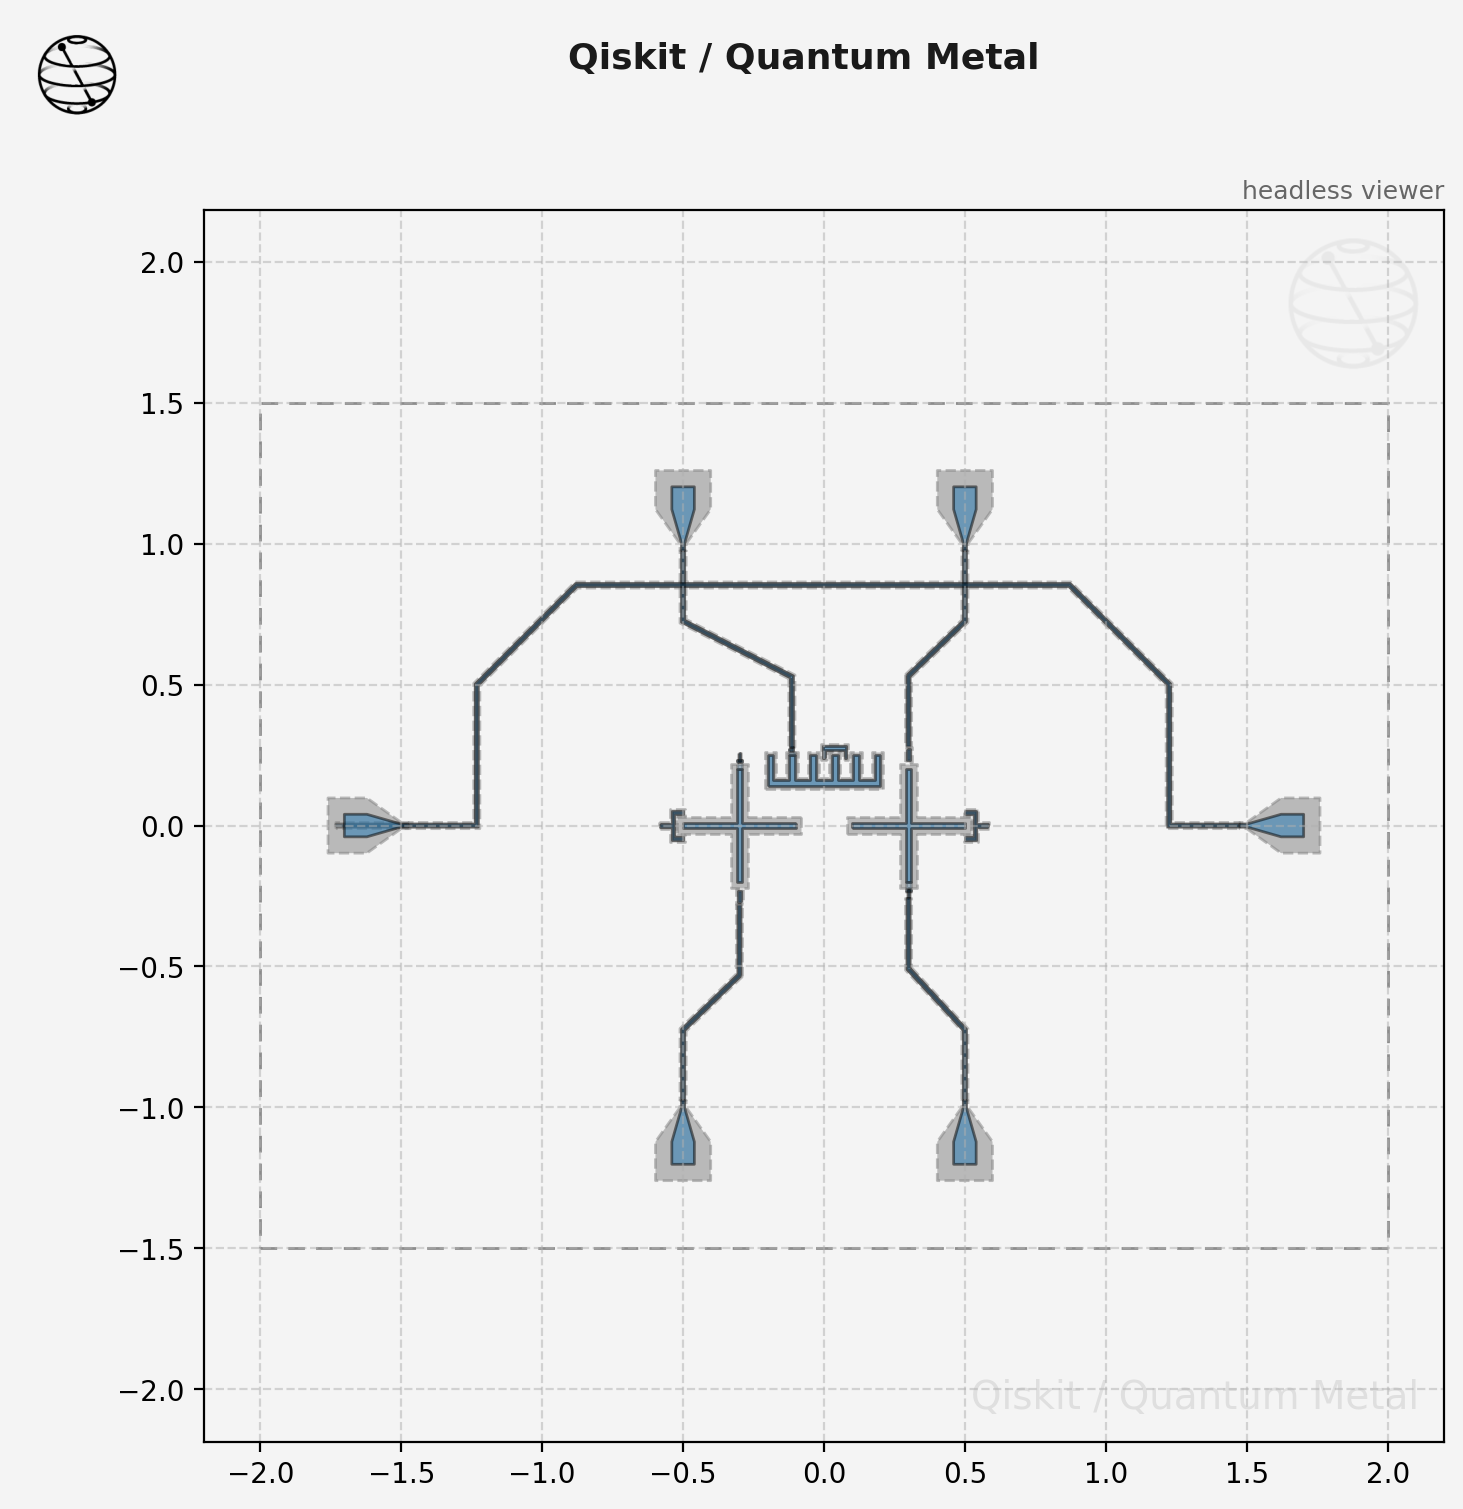

In [66]:
from collections import OrderedDict

jogs = OrderedDict()
jogs[0] = ["R", "0.5mm"]
jogs[1] = [45, "0.5mm"]
jogs[2] = [45, "1.75mm"]
jogs[3] = [45, "0.5mm"]
jogs[4] = [45, "0.5mm"]
jogs[5] = ["R", "0.5mm"]

options = Dict(
    total_length="4.75mm",
    pin_inputs=Dict(
        start_pin=Dict(component="T_east", pin="tie"),
        end_pin=Dict(component="T_west", pin="tie"),
    ),
    lead=Dict(
        start_straight="0.25mm", end_straight="0.1mm", start_jogged_extension=jogs
    ),
    # start_jogged_extension=jogs,
    # end_jogged_extension=jogs),
    meander=Dict(asymmetry="0.0mm"),
)


cpw5 = RouteMeander(design, "tline", options=options)
# cpw5 = RouteStraight(design,options=options)
gui.rebuild()
gui.autoscale()

Some of the CPWs are capacitively coupled to the main transmission line, so we will create several open-to-grounds at the appropriate locations for our CPWs to terminate:

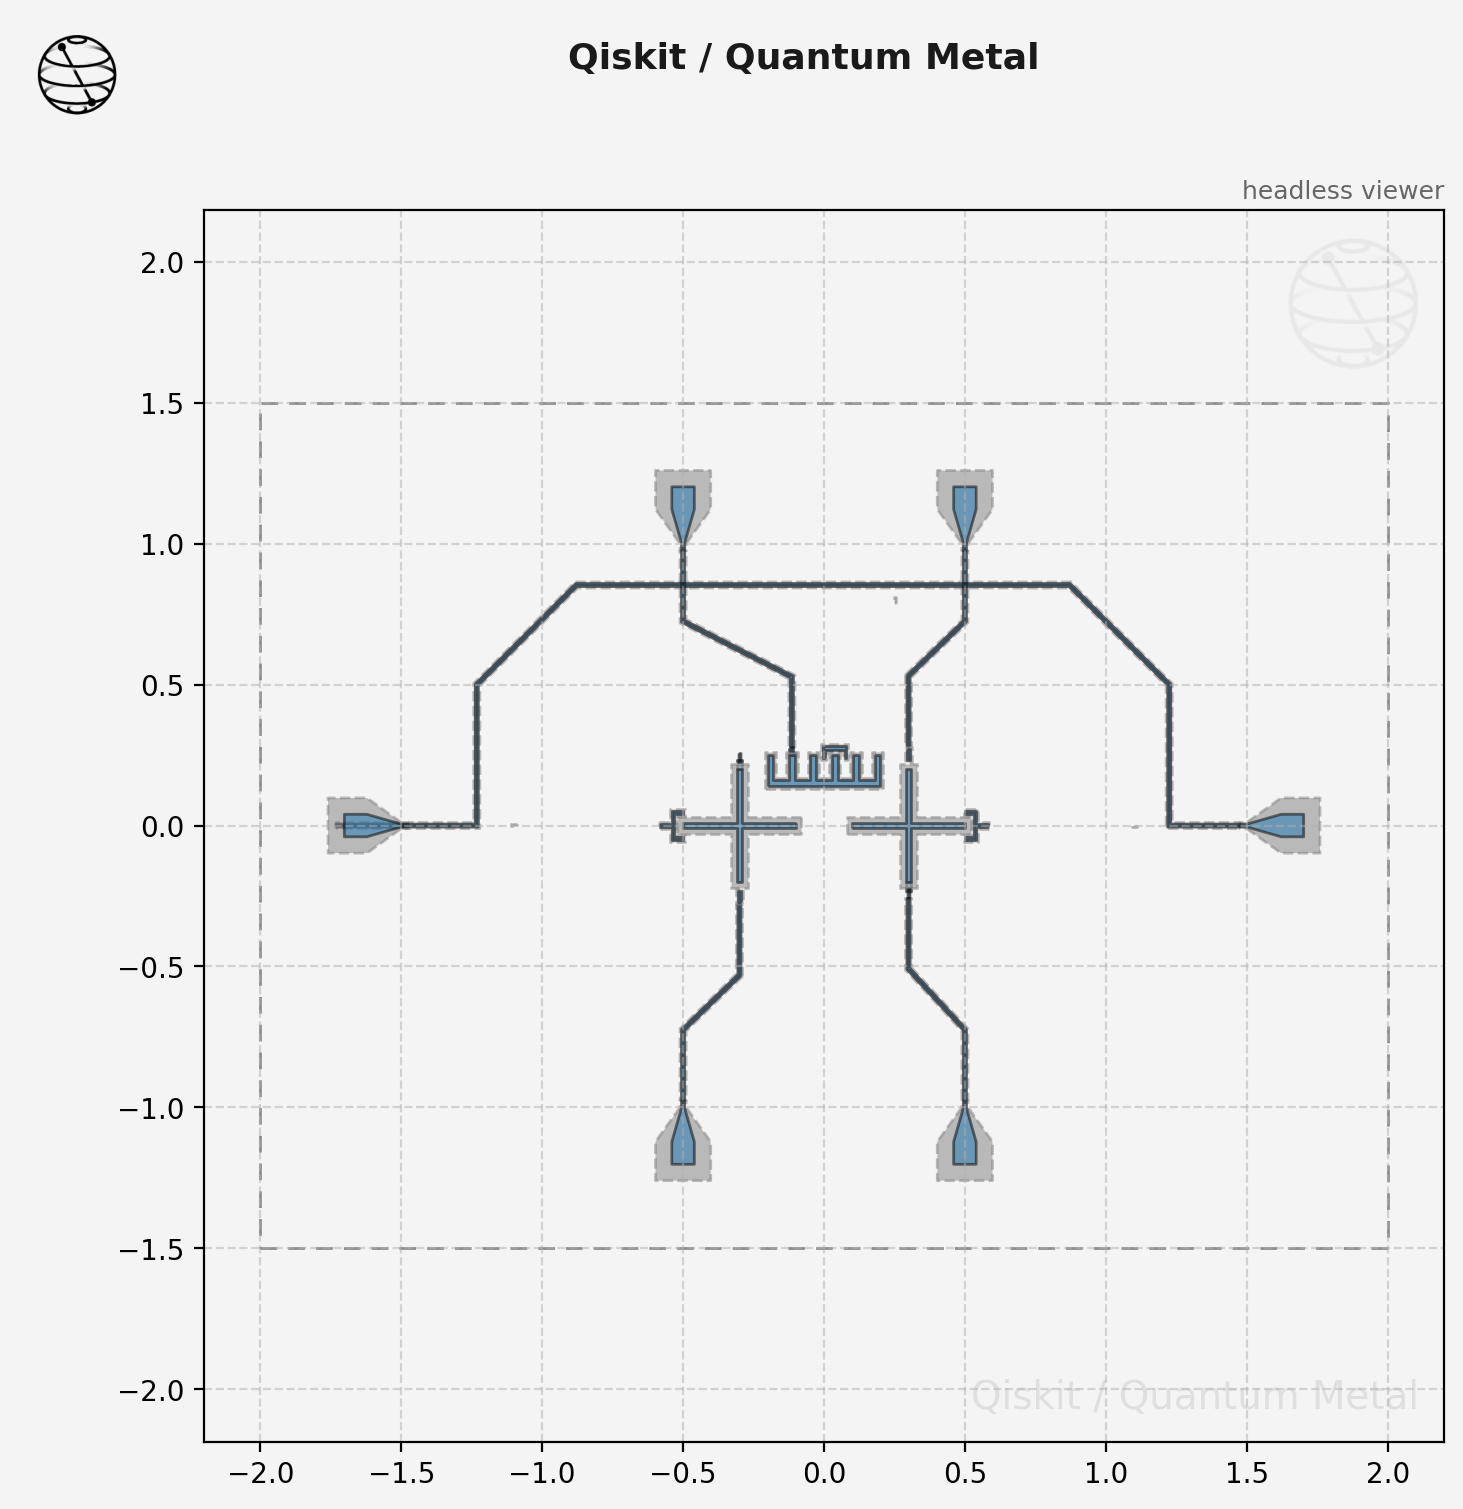

In [67]:
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround

otg1 = OpenToGround(
    design, "open1", options=dict(pos_x="0.25mm", pos_y="0.8mm", orientation="0")
)
otg2 = OpenToGround(
    design, "open2", options=dict(pos_x="1.1mm", pos_y="0.0mm", orientation="-90")
)
otg3 = OpenToGround(
    design, "open3", options=dict(pos_x="-1.1mm", pos_y="0.0mm", orientation="90")
)
gui.rebuild()
gui.autoscale()

Now we can route the meandering CPWs to create the capacitive coupling between the qubits/coupler and the main transmission line:

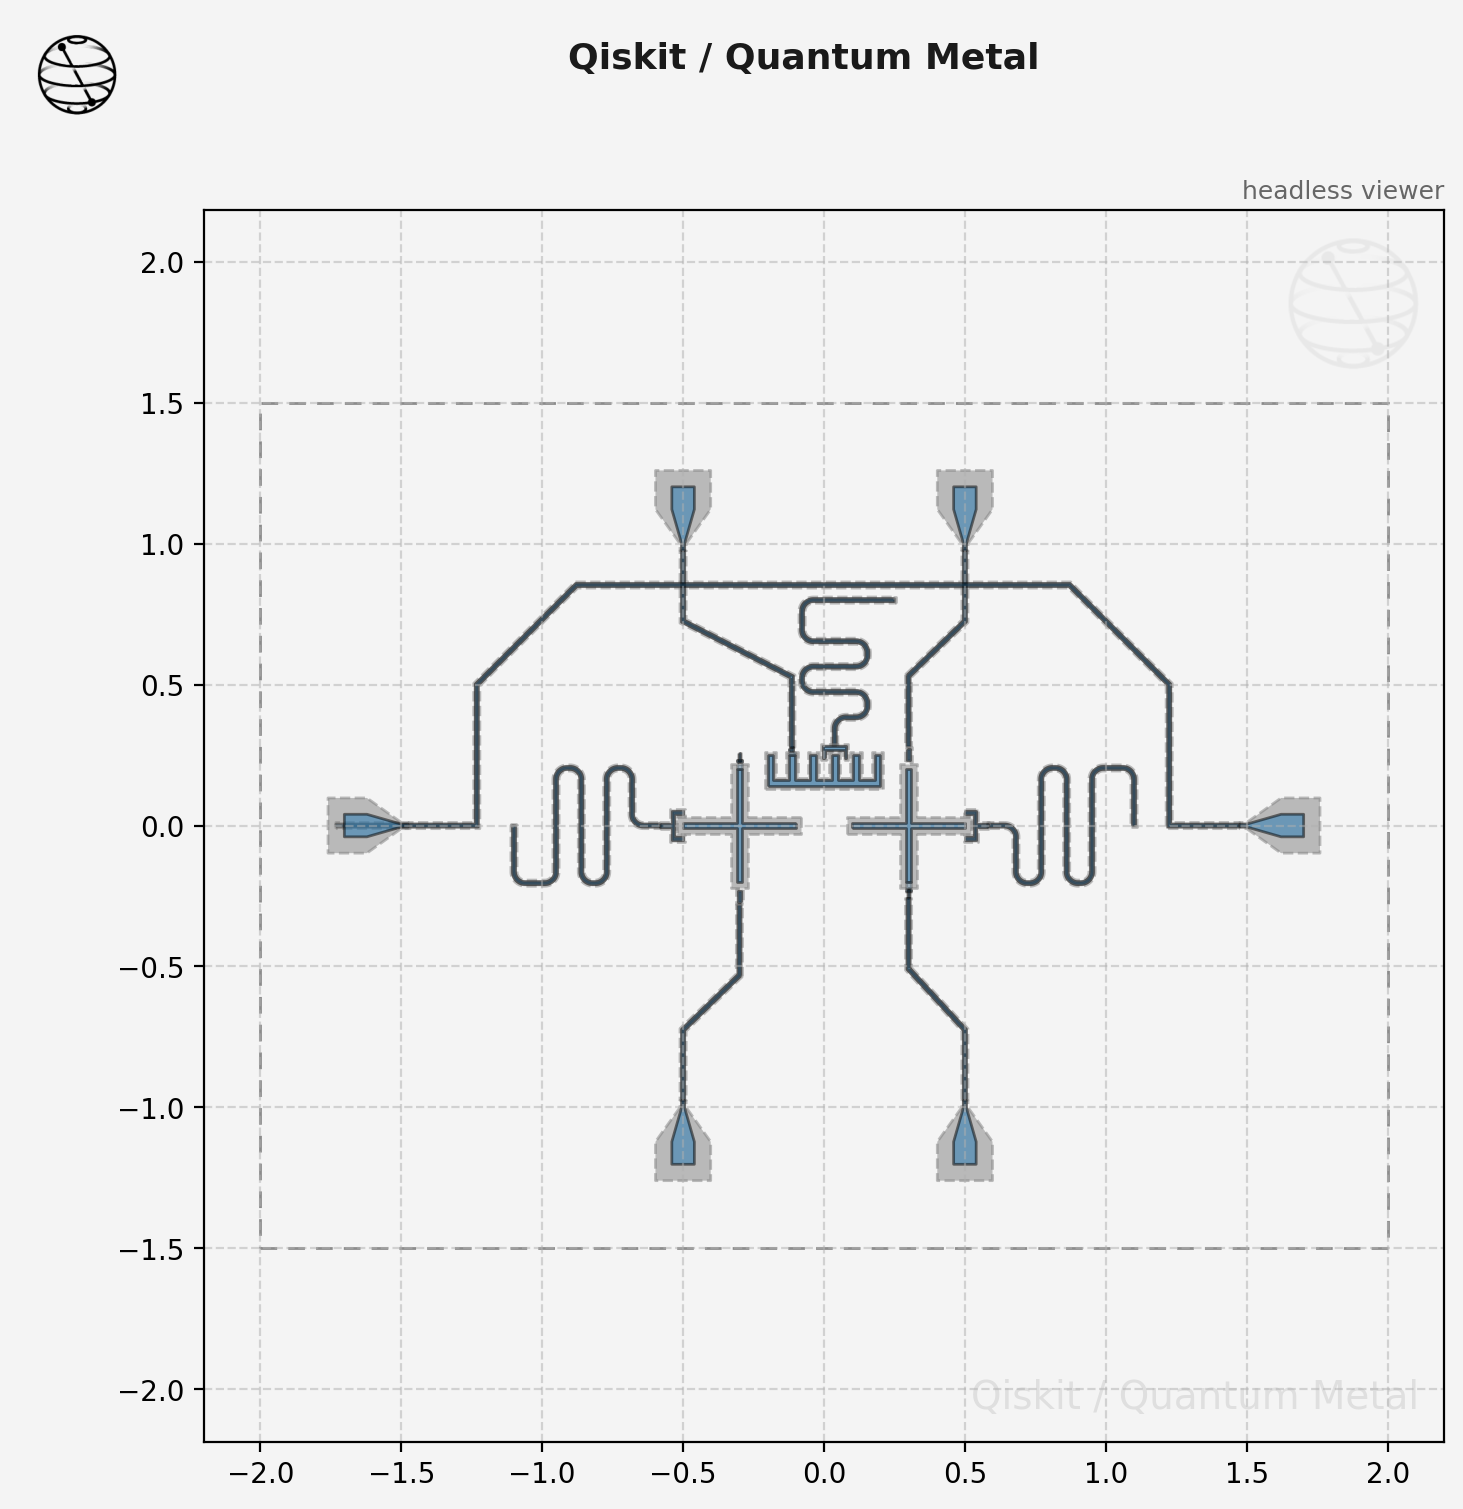

In [68]:
options2 = Dict(
    fillet="40um",
    total_length="1.5mm",
    pin_inputs=Dict(
        start_pin=Dict(component="TC", pin="Control"),
        end_pin=Dict(component="open1", pin="open"),
    ),
    lead=Dict(start_straight="0.1mm", end_straight="0.1mm"),
    meander=Dict(spacing="90um", asymmetry="0mm"),
)

coupler_middle = RouteMeander(design, "coupler_mid", options=options2)

options_right = Dict(
    fillet="40um",
    total_length="2mm",
    pin_inputs=Dict(
        start_pin=Dict(component="Q1", pin="c"),
        end_pin=Dict(component="open2", pin="open"),
    ),
    lead=Dict(start_straight="0.1mm", end_straight="0.1mm"),
    meander=Dict(spacing="90um", asymmetry="0mm"),
)

coupler_right = RouteMeander(design, "coupler_right", options=options_right)

options_left = Dict(
    fillet="40um",
    total_length="2mm",
    pin_inputs=Dict(
        start_pin=Dict(component="Q2", pin="c"),
        end_pin=Dict(component="open3", pin="open"),
    ),
    lead=Dict(start_straight="0.1mm", end_straight="0.1mm"),
    meander=Dict(spacing="90um", asymmetry="0mm"),
)

coupler_left = RouteMeander(design, "coupler_left", options=options_left)

gui.rebuild()
gui.autoscale()

Now the full chip design is complete. Here is a screenshot of the final design:

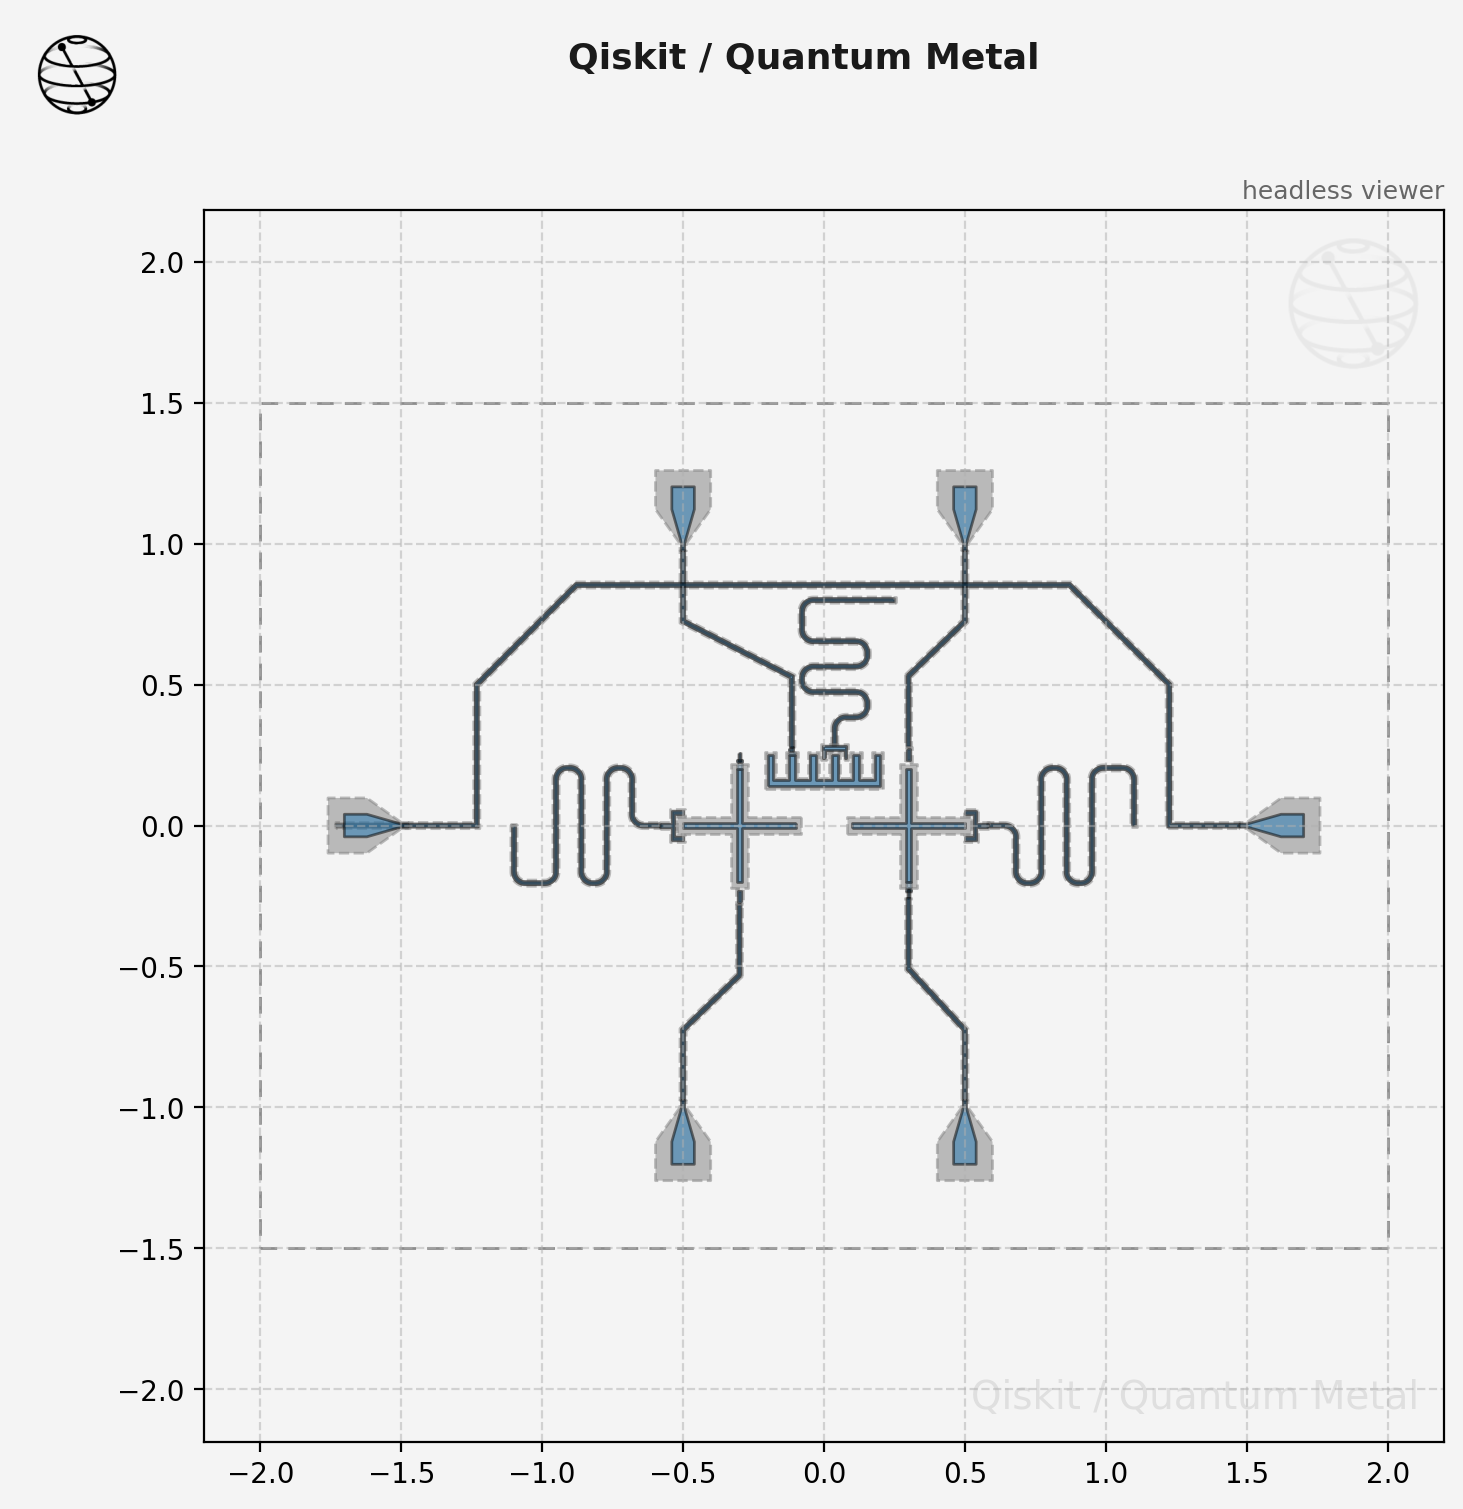

In [69]:
gui.screenshot()

The layout follows the device in Fig. 1 of Phys. Rev. X **11**, 021058 (2021).

## Where to go next

- [53 Wallraff 17-qubit surface code](53-Wallraff_17Qubit_SurfaceCode.ipynb) builds a larger chip in stages, with a design-rule check after each stage.
- [A.4 Full chip design](../full-design-flow-examples/A.4-Full-chip-design.ipynb) takes a chip from layout through capacitance, LOM and eigenmode analysis to GDS.
- Try it: run `from qiskit_metal.validation import validate; print(validate(design).report())` on each example to see where the layouts would need work before fabrication.